# Climate Change Twitter Dataset — Data Cleaning & Exploratory Data Analysis
### Group 23

**Dataset:** The Climate Change Twitter Dataset  
**Period:** 2006–2019  
**Main EDA question:** *How did the climate-change conversation on Twitter evolve over time, especially in terms of topics, stance, sentiment, and aggressiveness?*

This notebook performs:
- dataset inspection and data-quality checks,
- cleaning and feature engineering,
- missing-value analysis,
- temporal EDA,
- topic and stance analysis,
- sentiment analysis,
- aggressiveness analysis,
- interpretation of the main patterns for the Medium blog post.

> **Important:** The dataset contains more than 15 million tweets. To avoid exhausting memory, the full dataset is processed in chunks. The reported aggregate results still use the complete dataset.

### How this notebook maps to the proposal and the blog post

Sections 1–18 are the original cleaning and EDA. Sections 19–29 were added so that every question from our proposal slides is answered. One person (Maryam) runs the whole notebook; the blog write-up is split by section.

| Proposal question | Sections | Blog write-up owner |
|---|---|---|
| Cleaning: inspection, data-quality checks, cleaning strategy, missingness | 1–7 | Maryam |
| Q1 — How did the conversation change 2006–2019 (volume, topics, sentiment)? | 8, 10, 19, 20, 21 | Izza |
| Q3 — Did political topics grow, and did stance polarise / aggressiveness rise? | 11, 12, 16, 23 | Izza |
| Q2 — Are denier tweets more aggressive than believer tweets? | 9, 13, 14, 15, 17, 22, 24 | Izzah |
| Q4 — Does the gender gap in denial hold across regions? | 18, 25, 27 | Izzah (18, 25) + Noor (27) |
| Q5 — Are the same topics linked to denial/aggression in every region? | 22, 26, 28 | Noor |
| Q6 — Do unusually hot/cold months change what people discuss, by stance? | 29 | Noor |
| Key findings, limitations, conclusion | 30–32 | Maryam (everyone adds one bullet) |

## 1. Imports and notebook setup

In [1]:
import os
import zipfile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 2. Load the dataset

The Kaggle download is `archive.zip`. The code below works if `archive.zip` **or the extracted CSV** is beside the notebook, or if the ZIP is uploaded to Google Colab / available in `/mnt/data/`.

The ZIP also contains `disasters.csv`, but this EDA uses the main climate-change Twitter CSV.

In [2]:
csv_candidates = [
    "The Climate Change Twitter Dataset.csv",
    "climate_twitter_data/The Climate Change Twitter Dataset.csv",
]

CSV_PATH = next((p for p in csv_candidates if os.path.exists(p)), None)

if CSV_PATH is None:
    zip_candidates = [
        "archive.zip",
        "/content/archive.zip",
        "/mnt/data/archive.zip",
    ]

    ZIP_PATH = next((p for p in zip_candidates if os.path.exists(p)), None)

    if ZIP_PATH is None:
        raise FileNotFoundError(
            "Neither the CSV nor archive.zip was found. Put the Kaggle archive.zip (or the extracted CSV) beside the notebook."
        )

    extract_dir = os.path.join(os.path.dirname(ZIP_PATH), "climate_twitter_data")
    os.makedirs(extract_dir, exist_ok=True)

    CSV_PATH = os.path.join(extract_dir, "The Climate Change Twitter Dataset.csv")

    if not os.path.exists(CSV_PATH):
        with zipfile.ZipFile(ZIP_PATH, "r") as z:
            z.extract("The Climate Change Twitter Dataset.csv", extract_dir)

print("Using:", CSV_PATH)

Using: climate_twitter_data\The Climate Change Twitter Dataset.csv


## 3. Initial inspection

Loading all 15M+ rows at once is unnecessary for basic inspection, so we first inspect a 200,000-row sample.

In [3]:
sample = pd.read_csv(CSV_PATH, nrows=200_000)

print("Sample shape:", sample.shape)
print("\nColumns:")
print(list(sample.columns))

display(sample.head())

Sample shape: (200000, 10)

Columns:
['created_at', 'id', 'lng', 'lat', 'topic', 'sentiment', 'stance', 'gender', 'temperature_avg', 'aggressiveness']


,created_at,id,lng,lat,topic,sentiment,stance,gender,temperature_avg,aggressiveness
0,2006-06-06 16:06:42+00:00,6132,NaN,NaN,Weather Extremes,-0.097,neutral,female,NaN,aggressive
1,2006-07-23 21:52:30+00:00,13275,-73.950,40.650,Weather Extremes,0.576,neutral,undefined,-1.115,aggressive
2,2006-08-29 01:52:30+00:00,23160,NaN,NaN,Weather Extremes,0.500,neutral,male,NaN,aggressive
3,2006-11-07 02:46:52+00:00,57868,NaN,NaN,Weather Extremes,0.033,neutral,male,NaN,aggressive
4,2006-11-27 14:27:43+00:00,304553,NaN,NaN,Importance of Human Intervantion,-0.090,neutral,male,NaN,aggressive


In [4]:
sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   created_at       200000 non-null  str    
 1   id               200000 non-null  int64  
 2   lng              70704 non-null   float64
 3   lat              70704 non-null   float64
 4   topic            200000 non-null  str    
 5   sentiment        200000 non-null  float64
 6   stance           200000 non-null  str    
 7   gender           200000 non-null  str    
 8   temperature_avg  70704 non-null   float64
 9   aggressiveness   200000 non-null  str    
dtypes: float64(4), int64(1), str(5)
memory usage: 28.6 MB


### What the columns represent

- `created_at`: tweet timestamp
- `id`: tweet identifier
- `lng`, `lat`: geographic coordinates when available
- `topic`: climate-related topic assigned to the tweet
- `sentiment`: sentiment score
- `stance`: believer, denier, or neutral
- `gender`: inferred gender category
- `temperature_avg`: **temperature anomaly** — the deviation (°C) from the 1951–1980 average at the tweet's location and month, available only when location is available (it is *not* the raw temperature; the dataset paper defines it this way)
- `aggressiveness`: aggressive / not aggressive

The first cleaning concern is therefore not just *whether* data are missing, but *where* they are missing and whether imputing them would make sense.

## 4. Cleaning strategy

We use the following decisions:

1. Convert `created_at` to a proper datetime and derive `year`.
2. Keep tweet IDs as identifiers and check for duplicate IDs.
3. Convert numeric columns safely.
4. Validate sentiment and geographic ranges instead of silently changing them.
5. **Do not mean-impute latitude, longitude, or temperature.** Their missingness is structurally related: tweets without geographic coordinates also lack local temperature information. Inventing an average location or temperature would create fake data.
6. Keep tweets with missing geography for analyses that do not require location or temperature.
7. Fix one misspelled topic label in the source (`Importance of Human Intervantion`).
8. Derive a few helper features used by the added sections: a `month` period, a `sentiment_label` (negative / neutral / positive with a ±0.05 threshold), a coarse `region` from latitude/longitude bounding boxes, and a `temp_bin` that bins the temperature anomaly.

In [5]:
def clean_chunk(df):
    # Clean one chunk without changing the meaning of the original data.
    df = df.copy()

    df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce", utc=True)
    df["year"] = df["created_at"].dt.year.astype("Int64")
    df["month"] = df["created_at"].dt.tz_convert(None).dt.to_period("M")

    for col in ["lng", "lat", "sentiment", "temperature_avg"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    for col in ["topic", "stance", "gender", "aggressiveness"]:
        df[col] = df[col].astype("string").str.strip()

    # one topic label is misspelled in the source file
    df["topic"] = df["topic"].replace({"Importance of Human Intervantion": "Importance of Human Intervention"})

    # sentiment label: negative / neutral / positive (threshold +-0.05)
    df["sentiment_label"] = np.select(
        [df["sentiment"] < -0.05, df["sentiment"] > 0.05], ["negative", "positive"], default="neutral"
    )

    # coarse region from latitude/longitude bounding boxes (first match wins); missing when there is no location
    lat, lng = df["lat"], df["lng"]
    region_conditions = [
        (lat >= 15) & (lat <= 72) & (lng >= -170) & (lng <= -50),    # North America
        (lat >= -56) & (lat < 15) & (lng >= -92) & (lng <= -34),     # Latin America
        (lat >= 35) & (lat <= 72) & (lng >= -25) & (lng <= 45),      # Europe
        (lat >= -35) & (lat < 37) & (lng >= -18) & (lng <= 52),      # Africa & Middle East
        (lat >= -50) & (lat < -10) & (lng >= 110) & (lng <= 180),    # Oceania
        (lat >= -10) & (lat <= 80) & (lng > 45) & (lng <= 180),      # Asia
    ]
    region_names = ["North America", "Latin America", "Europe", "Africa & Middle East", "Oceania", "Asia"]
    df["region"] = np.select(region_conditions, region_names, default="Other")
    df.loc[lat.isna() | lng.isna(), "region"] = np.nan

    # temperature-anomaly bins (degrees C relative to the 1951-1980 average)
    df["temp_bin"] = pd.cut(
        df["temperature_avg"],
        bins=[-np.inf, -3, -1, 0, 1, 3, np.inf],
        labels=["<= -3", "-3 to -1", "-1 to 0", "0 to 1", "1 to 3", "> 3"],
    ).astype("string")

    return df

clean_sample = clean_chunk(sample)
display(clean_sample.head())

,created_at,id,lng,lat,topic,sentiment,stance,gender,temperature_avg,aggressiveness,year,month,sentiment_label,region,temp_bin
0,2006-06-06 16:06:42+00:00,6132,NaN,NaN,Weather Extremes,-0.097,neutral,female,NaN,aggressive,2006,2006-06,negative,NaN,<NA>
1,2006-07-23 21:52:30+00:00,13275,-73.950,40.650,Weather Extremes,0.576,neutral,undefined,-1.115,aggressive,2006,2006-07,positive,North America,-3 to -1
2,2006-08-29 01:52:30+00:00,23160,NaN,NaN,Weather Extremes,0.500,neutral,male,NaN,aggressive,2006,2006-08,positive,NaN,<NA>
3,2006-11-07 02:46:52+00:00,57868,NaN,NaN,Weather Extremes,0.033,neutral,male,NaN,aggressive,2006,2006-11,neutral,NaN,<NA>
4,2006-11-27 14:27:43+00:00,304553,NaN,NaN,Importance of Human Intervention,-0.090,neutral,male,NaN,aggressive,2006,2006-11,negative,NaN,<NA>


## 5. Full-dataset quality checks and aggregation

The next cell scans the **complete dataset in chunks**. During the same pass it creates all aggregate tables needed for EDA, so we do not repeatedly load hundreds of megabytes into memory.

In [6]:
CHUNK_SIZE = 500_000

usecols = [
    "created_at", "id", "lng", "lat", "topic",
    "sentiment", "stance", "gender",
    "temperature_avg", "aggressiveness"
]

total_rows = 0
missing = Counter()

year_counts = Counter()
topic_counts = Counter()
stance_counts = Counter()
gender_counts = Counter()
aggr_counts = Counter()

year_topic = Counter()
year_stance = Counter()
year_aggr = Counter()
stance_aggr = Counter()
topic_aggr = Counter()
topic_stance = Counter()

sent_sum = 0.0
sent_n = 0
sent_by_stance_sum = Counter()
sent_by_stance_n = Counter()
sent_by_topic_sum = Counter()
sent_by_topic_n = Counter()

invalid_sentiment = 0
invalid_lat = 0
invalid_lng = 0

# ---- added for the proposal questions (sections 19-28) ----
missing_pattern = Counter()              # which of lat / lng / temperature_avg are missing together
invalid_temp = 0                         # temperature anomaly outside [-15, 15] degC
snow_n = 0                               # tweets after Nov 2010 (IDs embed their creation time)
snow_agree = 0                           # ... whose ID-embedded time matches created_at within 24h
sent_hist = np.zeros(40)                 # histogram of sentiment, 40 bins from -1 to +1

month_counts = Counter()                 # Q1: monthly timeline
year_sentlabel = Counter()               # Q1: negative/neutral/positive share by year
sent_by_year_sum = Counter()
sent_by_year_n = Counter()

year_stance_aggr = Counter()             # Q3: aggressiveness over time, by stance
year_stance_pol_aggr = Counter()         # Q3: denier tweets, political vs other topics
topic_stance_aggr = Counter()            # Q2/Q5: aggressiveness by topic x stance

gender_stance = Counter()                # Q4: gender gap in denial
gender_aggr = Counter()

year_geo = Counter()                     # geolocation coverage by year
null_island = 0                          # exact (0, 0) coordinates
geo_grid = np.zeros((180, 360))          # 1-degree world grid of tweet counts (for the map)
region_counts = Counter()
region_stance = Counter()                # Q5
region_aggr = Counter()
region_gender_stance = Counter()         # Q4 by region
region_topic_stance = Counter()          # Q5
region_topic_aggr = Counter()

temp_n = 0                               # Q6: temperature anomaly
temp_sum = 0.0
temp_sumsq = 0.0
temp_min = np.inf
temp_max = -np.inf
temp_above_zero = 0
temp_hist = np.zeros(60)                 # histogram, 60 bins from -6 to +6 degC
temp_by_year_sum = Counter()
temp_by_year_n = Counter()
bin_counts = Counter()
bin_stance = Counter()
bin_aggr = Counter()
bin_topic = Counter()
bin_stance_topic = Counter()
bin_region_stance = Counter()
sent_by_bin_sum = Counter()
sent_by_bin_n = Counter()
corr = Counter()                         # running sums for the anomaly-vs-sentiment correlation

min_date = None
max_date = None

for chunk_no, raw in enumerate(
    pd.read_csv(CSV_PATH, usecols=usecols, chunksize=CHUNK_SIZE),
    start=1
):
    df = clean_chunk(raw)
    n = len(df)
    total_rows += n

    for col in usecols:
        missing[col] += int(df[col].isna().sum())

    valid_dates = df["created_at"].dropna()
    if not valid_dates.empty:
        chunk_min = valid_dates.min()
        chunk_max = valid_dates.max()
        min_date = chunk_min if min_date is None or chunk_min < min_date else min_date
        max_date = chunk_max if max_date is None or chunk_max > max_date else max_date

    year_counts.update(df["year"].dropna().astype(int).value_counts().to_dict())
    topic_counts.update(df["topic"].dropna().value_counts().to_dict())
    stance_counts.update(df["stance"].dropna().value_counts().to_dict())
    gender_counts.update(df["gender"].dropna().value_counts().to_dict())
    aggr_counts.update(df["aggressiveness"].dropna().value_counts().to_dict())

    temp = df.dropna(subset=["year"]).copy()
    temp["year"] = temp["year"].astype(int)

    year_topic.update(temp.groupby(["year", "topic"]).size().to_dict())
    year_stance.update(temp.groupby(["year", "stance"]).size().to_dict())
    year_aggr.update(temp.groupby(["year", "aggressiveness"]).size().to_dict())

    stance_aggr.update(df.groupby(["stance", "aggressiveness"]).size().to_dict())
    topic_aggr.update(df.groupby(["topic", "aggressiveness"]).size().to_dict())
    topic_stance.update(df.groupby(["topic", "stance"]).size().to_dict())

    s = df["sentiment"].dropna()
    sent_sum += float(s.sum())
    sent_n += int(s.count())
    invalid_sentiment += int(((s < -1) | (s > 1)).sum())

    g = df.dropna(subset=["stance", "sentiment"]).groupby("stance")["sentiment"].agg(["sum", "count"])
    for key, row in g.iterrows():
        sent_by_stance_sum[key] += float(row["sum"])
        sent_by_stance_n[key] += int(row["count"])

    g = df.dropna(subset=["topic", "sentiment"]).groupby("topic")["sentiment"].agg(["sum", "count"])
    for key, row in g.iterrows():
        sent_by_topic_sum[key] += float(row["sum"])
        sent_by_topic_n[key] += int(row["count"])

    lat = df["lat"].dropna()
    lng = df["lng"].dropna()
    invalid_lat += int(((lat < -90) | (lat > 90)).sum())
    invalid_lng += int(((lng < -180) | (lng > 180)).sum())

    # ---- added data-quality checks ----
    missing_pattern.update(df[["lat", "lng", "temperature_avg"]].isna().value_counts().to_dict())
    sent_hist += np.histogram(s, bins=40, range=(-1, 1))[0]

    # tweet IDs issued after Nov 2010 are 'snowflake' IDs that embed the creation time in milliseconds;
    # comparing that with created_at is a free consistency check on both columns
    snow = df[df["created_at"] >= pd.Timestamp("2010-11-05", tz="UTC")]
    if len(snow) > 0:
        id_time = pd.to_datetime((snow["id"].to_numpy().astype("int64") >> 22) + 1288834974657, unit="ms", utc=True)
        gap = (pd.Series(id_time, index=snow.index) - snow["created_at"]).abs()
        snow_n += len(snow)
        snow_agree += int((gap < pd.Timedelta("1D")).sum())

    # ---- added for the proposal questions (sections 19-29) ----
    month_counts.update(df["month"].dropna().value_counts().to_dict())

    year_sentlabel.update(temp.groupby(["year", "sentiment_label"]).size().to_dict())
    g = temp.groupby("year")["sentiment"].agg(["sum", "count"])
    for key, row in g.iterrows():
        sent_by_year_sum[key] += float(row["sum"])
        sent_by_year_n[key] += int(row["count"])

    year_stance_aggr.update(temp.groupby(["year", "stance", "aggressiveness"]).size().to_dict())
    temp["political"] = temp["topic"].isin(["Politics", "Donald Trump versus Science"])
    year_stance_pol_aggr.update(temp.groupby(["year", "stance", "political", "aggressiveness"]).size().to_dict())
    topic_stance_aggr.update(df.groupby(["topic", "stance", "aggressiveness"]).size().to_dict())

    gender_stance.update(df.groupby(["gender", "stance"]).size().to_dict())
    gender_aggr.update(df.groupby(["gender", "aggressiveness"]).size().to_dict())

    temp["has_geo"] = temp["lat"].notna() & temp["lng"].notna()
    year_geo.update(temp.groupby(["year", "has_geo"]).size().to_dict())
    null_island += int(((df["lat"] == 0) & (df["lng"] == 0)).sum())

    geo = df.dropna(subset=["lat", "lng"])
    h, _, _ = np.histogram2d(geo["lat"], geo["lng"], bins=[180, 360], range=[[-90, 90], [-180, 180]])
    geo_grid += h
    region_counts.update(geo["region"].value_counts().to_dict())
    region_stance.update(geo.groupby(["region", "stance"]).size().to_dict())
    region_aggr.update(geo.groupby(["region", "aggressiveness"]).size().to_dict())
    region_gender_stance.update(geo.groupby(["region", "gender", "stance"]).size().to_dict())
    region_topic_stance.update(geo.groupby(["region", "topic", "stance"]).size().to_dict())
    region_topic_aggr.update(geo.groupby(["region", "topic", "aggressiveness"]).size().to_dict())

    anom = df.dropna(subset=["temperature_avg"])
    t = anom["temperature_avg"]
    if len(t) > 0:
        temp_n += int(t.count())
        temp_sum += float(t.sum())
        temp_sumsq += float((t ** 2).sum())
        temp_min = min(temp_min, float(t.min()))
        temp_max = max(temp_max, float(t.max()))
        temp_above_zero += int((t > 0).sum())
        invalid_temp += int(((t < -15) | (t > 15)).sum())
        h, _ = np.histogram(t, bins=60, range=(-6, 6))
        temp_hist += h

    g = anom.dropna(subset=["year"]).groupby("year")["temperature_avg"].agg(["sum", "count"])
    for key, row in g.iterrows():
        temp_by_year_sum[int(key)] += float(row["sum"])
        temp_by_year_n[int(key)] += int(row["count"])

    bin_counts.update(anom["temp_bin"].value_counts().to_dict())
    bin_stance.update(anom.groupby(["temp_bin", "stance"]).size().to_dict())
    bin_aggr.update(anom.groupby(["temp_bin", "aggressiveness"]).size().to_dict())
    bin_topic.update(anom.groupby(["temp_bin", "topic"]).size().to_dict())
    bin_stance_topic.update(anom.groupby(["temp_bin", "stance", "topic"]).size().to_dict())
    bin_region_stance.update(anom.groupby(["temp_bin", "region", "stance"]).size().to_dict())

    g = anom.groupby("temp_bin")["sentiment"].agg(["sum", "count"])
    for key, row in g.iterrows():
        sent_by_bin_sum[key] += float(row["sum"])
        sent_by_bin_n[key] += int(row["count"])

    both = anom.dropna(subset=["sentiment"])
    x, y = both["temperature_avg"], both["sentiment"]
    corr["n"] += len(both)
    corr["x"] += float(x.sum());  corr["xx"] += float((x ** 2).sum())
    corr["y"] += float(y.sum());  corr["yy"] += float((y ** 2).sum())
    corr["xy"] += float((x * y).sum())

    if chunk_no % 10 == 0:
        print(f"Processed {total_rows:,} rows")

print(f"\nTotal rows: {total_rows:,}")
print("Date range:", min_date, "to", max_date)

Processed 5,000,000 rows
Processed 10,000,000 rows
Processed 15,000,000 rows

Total rows: 15,789,411
Date range: 2006-06-06 16:06:42+00:00 to 2019-10-01 05:57:52+00:00


### Duplicate tweet IDs

Because the identifier column is much smaller than the full 10-column dataset, we can check it exactly without loading every feature at once.

In [7]:
ids = pd.read_csv(CSV_PATH, usecols=["id"])
duplicate_ids = int(ids["id"].duplicated().sum())
del ids

print("Duplicate tweet IDs:", duplicate_ids)

Duplicate tweet IDs: 0


In [38]:
# Audit check: are the 4,392 anomaly values beyond ±15 °C real extremes or a sentinel (e.g. -99)?
t = pd.read_csv(CSV_PATH, usecols=["temperature_avg"])["temperature_avg"].dropna()
print(t.describe())
print(t[t.abs() > 15].round(0).value_counts().head(10))

count   5,307,538.000
mean            1.245
std             3.800
min           -23.289
25%            -1.141
50%             1.212
75%             3.867
max            21.004
Name: temperature_avg, dtype: float64
temperature_avg
15.000     845
16.000     817
-16.000    713
-15.000    630
-17.000    599
17.000     292
-18.000    174
18.000     117
19.000      68
-19.000     55
Name: count, dtype: int64


## 6. Missing values and validation

In [8]:
missing_df = pd.DataFrame({
    "column": usecols,
    "missing_count": [missing[c] for c in usecols],
})
missing_df["missing_percent"] = missing_df["missing_count"] / total_rows * 100
missing_df = missing_df.sort_values("missing_percent", ascending=False)

display(missing_df)

,column,missing_count,missing_percent
3,lat,10481873,66.385
2,lng,10481873,66.385
8,temperature_avg,10481873,66.385
0,created_at,0,0.000
1,id,0,0.000
4,topic,0,0.000
5,sentiment,0,0.000
6,stance,0,0.000
7,gender,0,0.000
9,aggressiveness,0,0.000


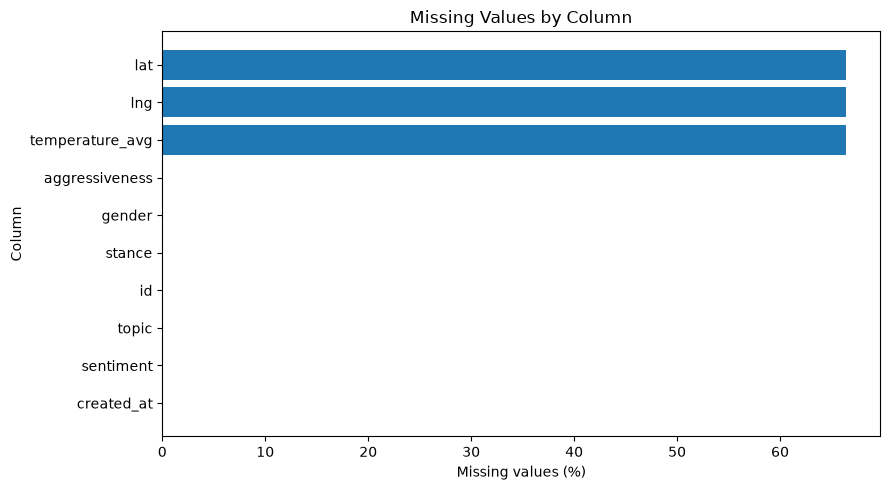

In [9]:
plot_df = missing_df.sort_values("missing_percent")

plt.figure(figsize=(9, 5))
plt.barh(plot_df["column"], plot_df["missing_percent"])
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Missing Values by Column")
plt.tight_layout()
plt.show()

In [10]:
print("Invalid sentiment scores outside [-1, 1]:", invalid_sentiment)
print("Invalid latitude values outside [-90, 90]:", invalid_lat)
print("Invalid longitude values outside [-180, 180]:", invalid_lng)
print("Duplicate tweet IDs:", duplicate_ids)
print("Exact (0, 0) coordinates ('Null Island', a geocoder failure value):", null_island)
print("Temperature anomaly outside [-15, 15] C:", invalid_temp)
print(f"Tweets after Nov 2010 whose ID-embedded time matches created_at within 24h: "
      f"{snow_agree:,} of {snow_n:,} ({snow_agree / snow_n * 100:.2f}%)")

print("\nMissingness pattern of lat / lng / temperature_avg (True = missing):")
pattern_df = pd.DataFrame(
    [(*k, v) for k, v in missing_pattern.items()],
    columns=["lat_missing", "lng_missing", "temperature_avg_missing", "rows"]
).sort_values("rows", ascending=False)
pattern_df["percent"] = pattern_df["rows"] / total_rows * 100
display(pattern_df)

Invalid sentiment scores outside [-1, 1]: 0
Invalid latitude values outside [-90, 90]: 0
Invalid longitude values outside [-180, 180]: 0
Duplicate tweet IDs: 0
Exact (0, 0) coordinates ('Null Island', a geocoder failure value): 40
Temperature anomaly outside [-15, 15] C: 4392
Tweets after Nov 2010 whose ID-embedded time matches created_at within 24h: 14,870,285 of 14,870,285 (100.00%)

Missingness pattern of lat / lng / temperature_avg (True = missing):


,lat_missing,lng_missing,temperature_avg_missing,rows,percent
0,True,True,True,10481873,66.385
1,False,False,False,5307538,33.615


### Interpretation

The full dataset has **15,789,411 tweets**. Approximately **66.39%** of `lat`, `lng`, and `temperature_avg` values are missing, while the core fields used in this EDA are complete.

The geographic and temperature missingness occurs together: the missingness-pattern table shows only two patterns, **10,481,873 rows with all three missing** and **5,307,538 with all three present**. No row has coordinates without a temperature, or the other way round, so we treat this as structural missingness rather than replacing it with averages.

We also found **0 duplicate tweet IDs**, no sentiment scores outside `[-1, 1]`, and no latitude/longitude values outside valid ranges. Two small quirks:

- **40 tweets** sit at exactly (0, 0), "Null Island", a value geocoders return when they fail.
- **4,392 tweets** (0.08% of located tweets) have a temperature anomaly beyond ±15 °C. The check above shows they spread smoothly out to −23.3 and +21.0 °C rather than repeating one sentinel value, so they are real extremes and we kept them.

Finally, all **14,870,285** tweets after November 2010 have an ID-embedded creation time within 24 hours of `created_at` (100.00%), so the timestamps are consistent with the tweet IDs.

This means the dataset needs relatively little destructive cleaning: the most important steps are correct datatype conversion, feature engineering, validation, and using appropriate subsets for analyses involving location or temperature.

## 7. Build EDA summary tables

In [11]:
years = sorted(year_counts)

year_df = pd.DataFrame({
    "year": years,
    "tweets": [year_counts[y] for y in years]
})
year_df["percent_of_all_tweets"] = year_df["tweets"] / total_rows * 100

stance_df = pd.DataFrame(
    stance_counts.items(), columns=["stance", "count"]
).sort_values("count", ascending=False)
stance_df["percent"] = stance_df["count"] / total_rows * 100

topic_df = pd.DataFrame(
    topic_counts.items(), columns=["topic", "count"]
).sort_values("count", ascending=False)
topic_df["percent"] = topic_df["count"] / total_rows * 100

gender_df = pd.DataFrame(
    gender_counts.items(), columns=["gender", "count"]
).sort_values("count", ascending=False)
gender_df["percent"] = gender_df["count"] / total_rows * 100

yt = pd.Series(year_topic).rename("count").reset_index()
yt.columns = ["year", "topic", "count"]
yt["year_total"] = yt.groupby("year")["count"].transform("sum")
yt["percent"] = yt["count"] / yt["year_total"] * 100

ys = pd.Series(year_stance).rename("count").reset_index()
ys.columns = ["year", "stance", "count"]
ys["year_total"] = ys.groupby("year")["count"].transform("sum")
ys["percent"] = ys["count"] / ys["year_total"] * 100

ya = pd.Series(year_aggr).rename("count").reset_index()
ya.columns = ["year", "aggressiveness", "count"]
ya["year_total"] = ya.groupby("year")["count"].transform("sum")
ya["percent"] = ya["count"] / ya["year_total"] * 100

sa = pd.Series(stance_aggr).rename("count").reset_index()
sa.columns = ["stance", "aggressiveness", "count"]
sa["group_total"] = sa.groupby("stance")["count"].transform("sum")
sa["percent"] = sa["count"] / sa["group_total"] * 100

ta = pd.Series(topic_aggr).rename("count").reset_index()
ta.columns = ["topic", "aggressiveness", "count"]
ta["group_total"] = ta.groupby("topic")["count"].transform("sum")
ta["percent"] = ta["count"] / ta["group_total"] * 100

sentiment_by_stance = pd.DataFrame({
    "stance": list(sent_by_stance_sum.keys()),
    "mean_sentiment": [
        sent_by_stance_sum[k] / sent_by_stance_n[k]
        for k in sent_by_stance_sum
    ]
}).sort_values("mean_sentiment", ascending=False)

sentiment_by_topic = pd.DataFrame({
    "topic": list(sent_by_topic_sum.keys()),
    "mean_sentiment": [
        sent_by_topic_sum[k] / sent_by_topic_n[k]
        for k in sent_by_topic_sum
    ]
}).sort_values("mean_sentiment", ascending=False)

display(year_df)

,year,tweets,percent_of_all_tweets
0,2006,12,0.000
1,2007,3961,0.025
2,2008,29980,0.190
3,2009,489069,3.097
4,2010,447887,2.837
5,2011,317864,2.013
6,2012,198691,1.258
7,2013,282476,1.789
8,2014,408451,2.587
9,2015,1259359,7.976


# Exploratory Data Analysis

## 8. How did the volume of climate tweets change over time?

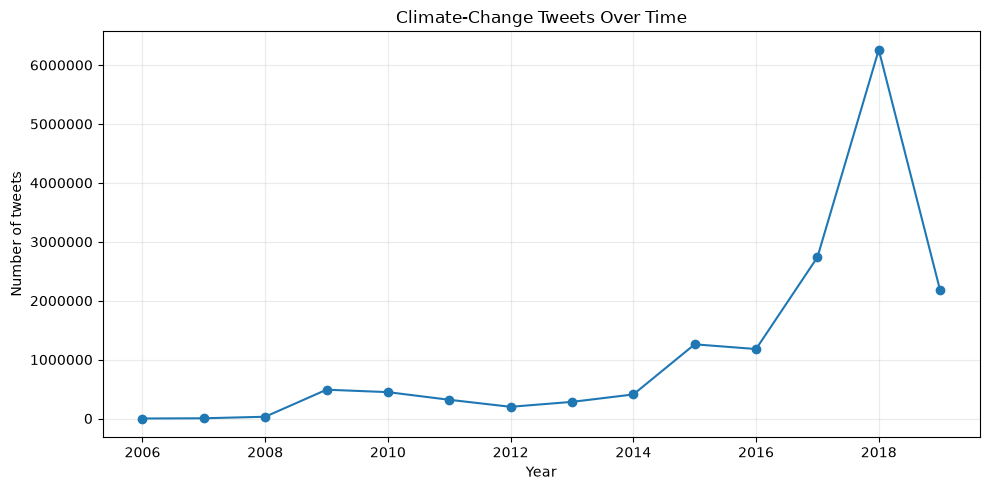

In [12]:
plt.figure(figsize=(10, 5))
plt.plot(year_df["year"], year_df["tweets"], marker="o")
plt.xlabel("Year")
plt.ylabel("Number of tweets")
plt.title("Climate-Change Tweets Over Time")
plt.ticklabel_format(style="plain", axis="y")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretation

Tweet volume is extremely uneven across time. The dataset starts with very few observations in 2006–2008, grows substantially from 2009 onward, and becomes especially large in the later years.

**2018 alone contains about 39.6% of all tweets in the dataset.** Therefore, raw counts can be misleading when comparing categories across years. In later analyses we often use **within-year percentages** so that a large year such as 2018 does not automatically dominate every result.

The tiny number of tweets in the earliest years also means percentages from 2006–2008 should be interpreted cautiously.

## 9. What stance dominates the climate conversation?

,stance,count,percent
0,believer,11292424,71.519
1,neutral,3305601,20.936
2,denier,1191386,7.545


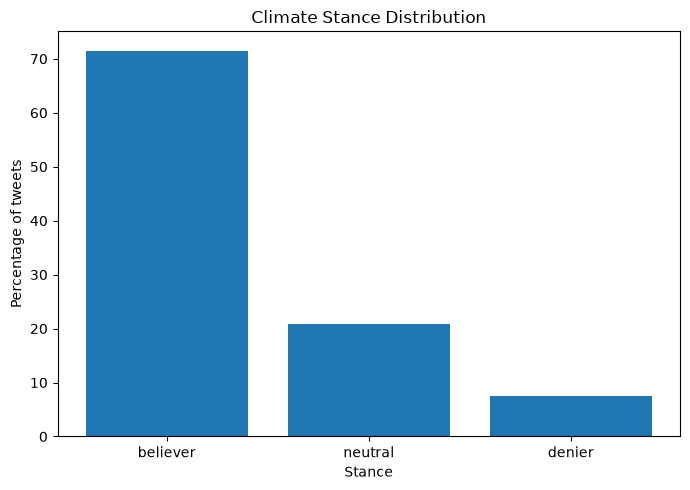

In [13]:
display(stance_df)

plt.figure(figsize=(7, 5))
plt.bar(stance_df["stance"], stance_df["percent"])
plt.ylabel("Percentage of tweets")
plt.xlabel("Stance")
plt.title("Climate Stance Distribution")
plt.tight_layout()
plt.show()

### Interpretation

The dataset is dominated by tweets classified as **believer (71.5%)**, followed by **neutral (20.9%)** and **denier (7.5%)**.

This imbalance matters for later comparisons. A raw count of believer tweets will naturally be larger, so comparisons between stance groups should usually use rates or percentages rather than counts alone.

## 10. What topics appear most often?

,topic,count,percent
0,Global stance,4135619,26.192
2,Importance of Human Intervention,2594941,16.435
1,Weather Extremes,2464814,15.611
3,Politics,1809583,11.461
7,Undefined / One Word Hashtags,1305118,8.266
4,Donald Trump versus Science,996244,6.310
5,Seriousness of Gas Emissions,903478,5.722
6,Ideological Positions on Global Warming,602695,3.817
8,Impact of Resource Overconsumption,496924,3.147
9,Significance of Pollution Awareness Events,479995,3.040


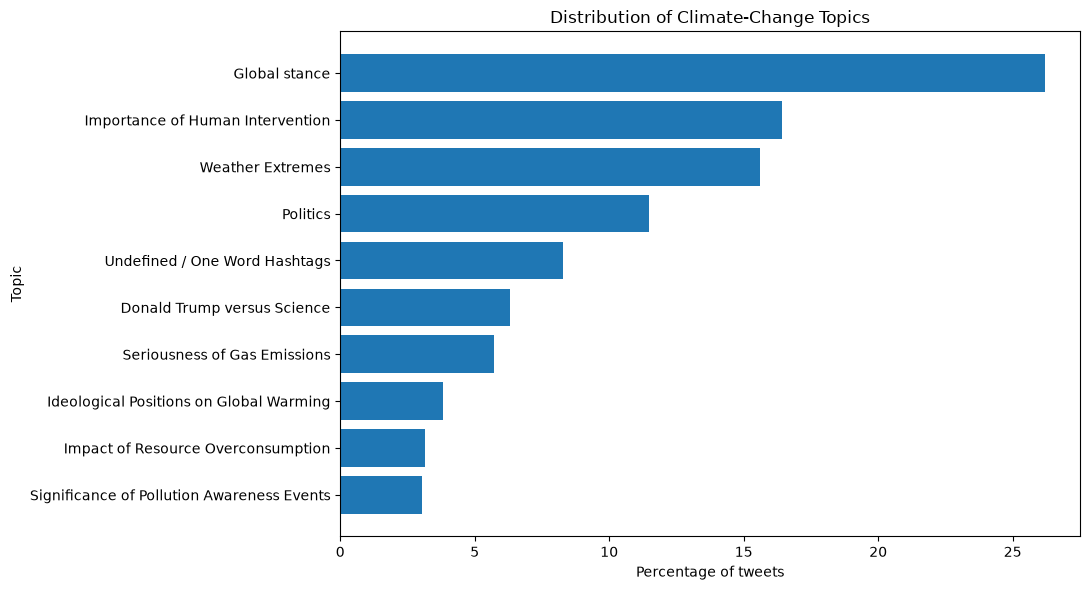

In [14]:
display(topic_df)

plot_topics = topic_df.sort_values("percent")

plt.figure(figsize=(11, 6))
plt.barh(plot_topics["topic"], plot_topics["percent"])
plt.xlabel("Percentage of tweets")
plt.ylabel("Topic")
plt.title("Distribution of Climate-Change Topics")
plt.tight_layout()
plt.show()

### Interpretation

The most common category is **Global stance (26.2%)**, followed by **Importance of Human Intervention (16.4%)** and **Weather Extremes (15.6%)**.

Political discussion is also substantial:
- **Politics:** about **11.5%**
- **Donald Trump versus Science:** about **6.3%**

Together, these categories show that a meaningful part of the climate conversation in the dataset is explicitly political.

## 11. Did political topics become more prominent over time?

Because tweet volume differs dramatically by year, we plot each topic as a **percentage of that year's climate tweets**, not as a raw count.

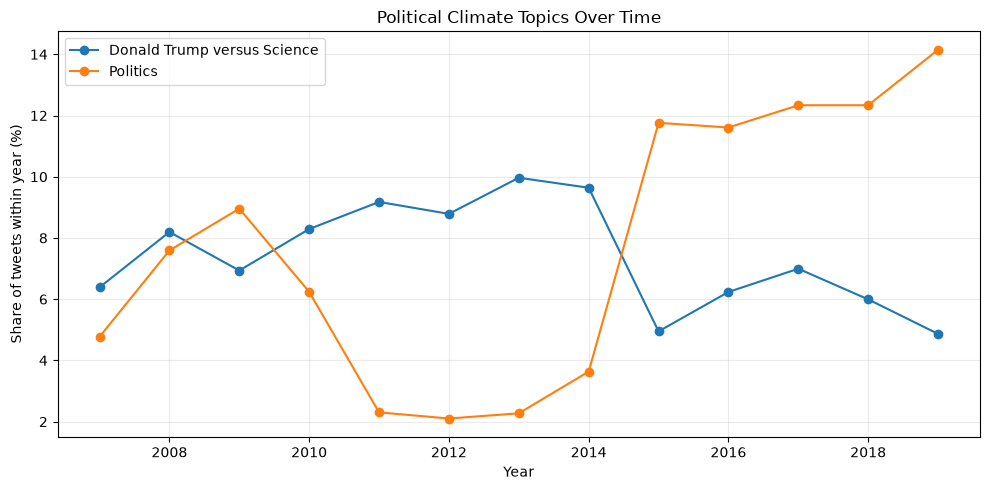

In [15]:
political_topics = yt[
    yt["topic"].isin(["Politics", "Donald Trump versus Science"])
].copy()

pivot_pol = political_topics.pivot(
    index="year", columns="topic", values="percent"
)

plt.figure(figsize=(10, 5))
for col in pivot_pol.columns:
    plt.plot(pivot_pol.index, pivot_pol[col], marker="o", label=col)

plt.xlabel("Year")
plt.ylabel("Share of tweets within year (%)")
plt.title("Political Climate Topics Over Time")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretation

The results are more nuanced than a simple “politics always increased” story.

The **Politics** category becomes much more prominent after 2014: it accounts for roughly **11.8% in 2015**, about **12.3% in 2017–2018**, and **14.2% in 2019**.

However, **Donald Trump versus Science** does **not** show a simple continuous increase. Its share was already relatively high in several earlier years and peaks around 2013 in this dataset before becoming a smaller share later.

So the evidence supports a rise in the broader **Politics** topic in later years, but not a monotonic rise in every political category.

## 12. How did stance composition change over time?

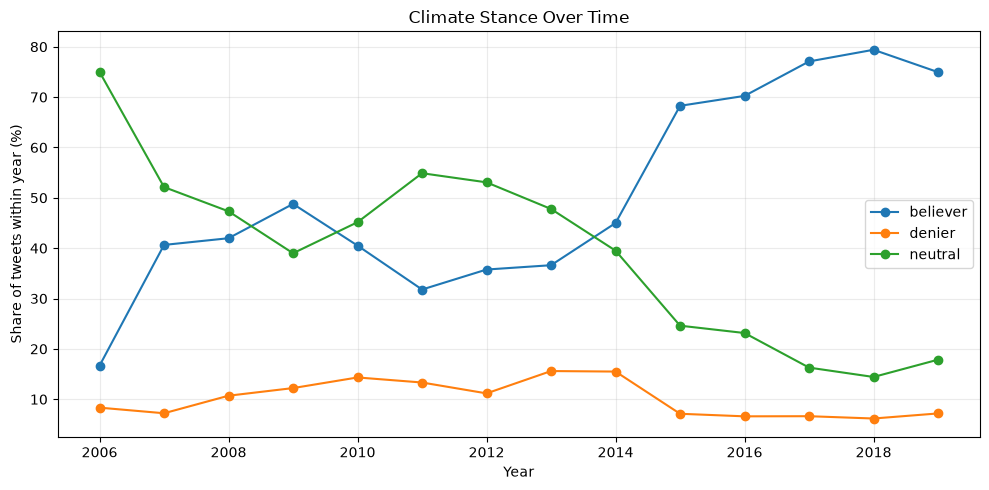

In [16]:
pivot_stance = ys.pivot(index="year", columns="stance", values="percent")

plt.figure(figsize=(10, 5))
for col in pivot_stance.columns:
    plt.plot(pivot_stance.index, pivot_stance[col], marker="o", label=col)

plt.xlabel("Year")
plt.ylabel("Share of tweets within year (%)")
plt.title("Climate Stance Over Time")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretation

The stance composition changes strongly over time. In the earlier years, neutral tweets make up a much larger share of the dataset. From 2015 onward, tweets classified as believers become dominant.

For example:
- believer tweets are about **68.3%** of tweets in 2015,
- about **77.1%** in 2017,
- and about **79.4%** in 2018.

The denier share does not steadily increase; it is actually lower in many later years than in 2009–2014. This suggests that “polarization” should not simply be defined as a growing denier share.

## 13. Sentiment by climate stance

,stance,mean_sentiment
2,neutral,0.038
0,believer,0.017
1,denier,-0.232


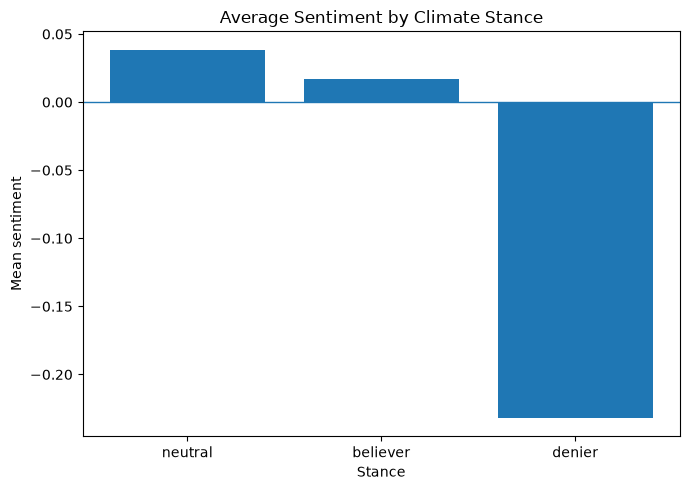

In [17]:
display(sentiment_by_stance)

plt.figure(figsize=(7, 5))
plt.bar(
    sentiment_by_stance["stance"],
    sentiment_by_stance["mean_sentiment"]
)
plt.axhline(0, linewidth=1)
plt.xlabel("Stance")
plt.ylabel("Mean sentiment")
plt.title("Average Sentiment by Climate Stance")
plt.tight_layout()
plt.show()

### Interpretation

Denier tweets have a noticeably more negative average sentiment (**about -0.232**) than believer (**about 0.017**) or neutral tweets (**about 0.039**).

This is an association in the dataset, not proof that stance *causes* sentiment. Still, it provides a useful descriptive difference between the three groups.

## 14. Are deniers more aggressive than believers?

,stance,percent
2,denier,42.646
4,neutral,28.211
0,believer,27.334


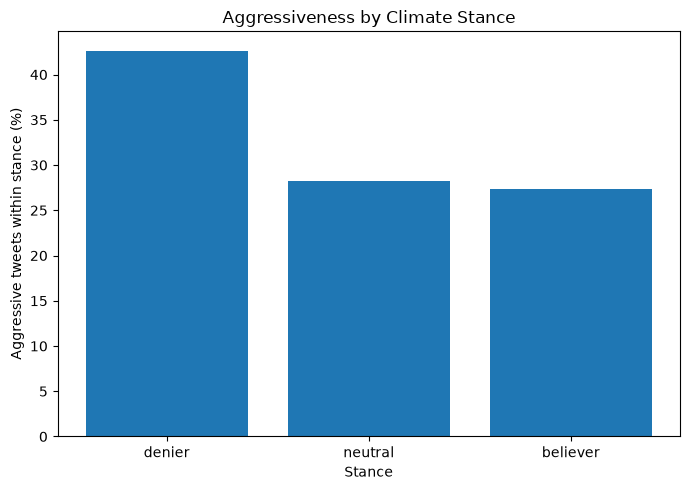

In [18]:
aggressive_by_stance = (
    sa[sa["aggressiveness"] == "aggressive"]
    [["stance", "percent"]]
    .sort_values("percent", ascending=False)
)

display(aggressive_by_stance)

plt.figure(figsize=(7, 5))
plt.bar(
    aggressive_by_stance["stance"],
    aggressive_by_stance["percent"]
)
plt.xlabel("Stance")
plt.ylabel("Aggressive tweets within stance (%)")
plt.title("Aggressiveness by Climate Stance")
plt.tight_layout()
plt.show()

### Interpretation

This is one of the clearest patterns in the EDA:

- **Denier:** about **42.6%** aggressive
- **Neutral:** about **28.2%** aggressive
- **Believer:** about **27.3%** aggressive

Tweets classified as deniers are therefore much more likely to also be classified as aggressive than believer or neutral tweets.

Again, this is a descriptive association between dataset labels and should not be interpreted as a causal relationship.

## 15. Which topics are most aggressive?

,topic,percent
10,Politics,43.393
0,Donald Trump versus Science,40.300
4,Ideological Positions on Global Warming,34.880
6,Impact of Resource Overconsumption,31.816
8,Importance of Human Intervention,28.720
12,Seriousness of Gas Emissions,26.229
16,Undefined / One Word Hashtags,25.675
18,Weather Extremes,24.321
2,Global stance,23.670
14,Significance of Pollution Awareness Events,15.949


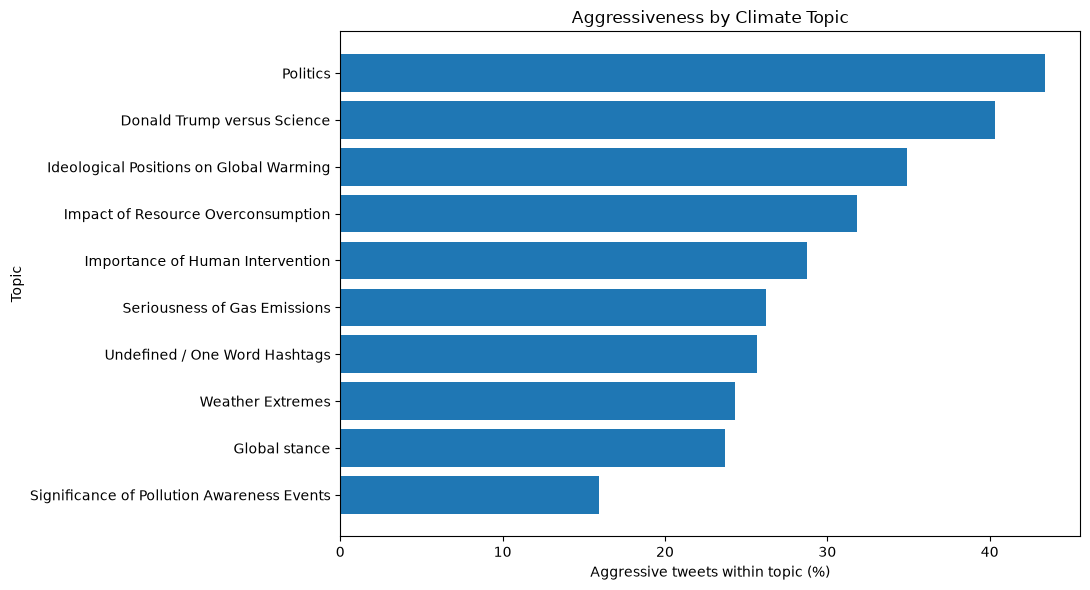

In [19]:
aggressive_by_topic = (
    ta[ta["aggressiveness"] == "aggressive"]
    [["topic", "percent"]]
    .sort_values("percent", ascending=True)
)

display(aggressive_by_topic.sort_values("percent", ascending=False))

plt.figure(figsize=(11, 6))
plt.barh(
    aggressive_by_topic["topic"],
    aggressive_by_topic["percent"]
)
plt.xlabel("Aggressive tweets within topic (%)")
plt.ylabel("Topic")
plt.title("Aggressiveness by Climate Topic")
plt.tight_layout()
plt.show()

### Interpretation

Political topics stand out strongly:

- **Politics:** about **43.4%** aggressive
- **Donald Trump versus Science:** about **40.3%** aggressive

These are the two highest aggressive shares among the listed topics. This supports the idea that political climate discussion in this dataset is more confrontational than many scientific, environmental, or awareness-oriented topics.

## 16. Did climate discussion become more aggressive over time?

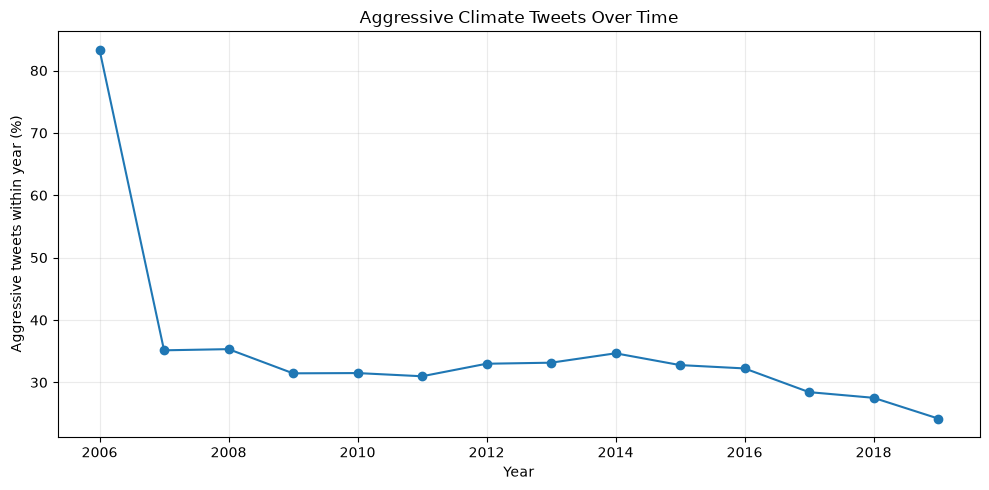

In [20]:
aggressive_over_time = (
    ya[ya["aggressiveness"] == "aggressive"]
    [["year", "percent"]]
    .sort_values("year")
)

plt.figure(figsize=(10, 5))
plt.plot(
    aggressive_over_time["year"],
    aggressive_over_time["percent"],
    marker="o"
)
plt.xlabel("Year")
plt.ylabel("Aggressive tweets within year (%)")
plt.title("Aggressive Climate Tweets Over Time")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretation

This result is especially interesting because it challenges a possible initial hypothesis.

Although political topics are among the most aggressive categories, **overall aggressiveness does not rise steadily over time**. After the mid-2010s, the aggressive share decreases:
- about **32.8%** in 2015,
- **28.4%** in 2017,
- **27.5%** in 2018,
- and **24.2%** in 2019.

Therefore, it would be misleading to write that climate Twitter simply became more aggressive as politics became more prominent. A better conclusion is:

> **Political climate topics are comparatively aggressive, but the overall proportion of aggressive tweets declines in the later years of the dataset.**

This contrast is useful for the Medium story because it shows why EDA is needed before accepting an intuitive hypothesis.

## 17. Sentiment across topics

,topic,mean_sentiment
8,Undefined / One Word Hashtags,0.241
4,Importance of Human Intervention,0.070
1,Global stance,0.069
7,Significance of Pollution Awareness Events,-0.029
6,Seriousness of Gas Emissions,-0.048
9,Weather Extremes,-0.082
5,Politics,-0.085
3,Impact of Resource Overconsumption,-0.104
0,Donald Trump versus Science,-0.160
2,Ideological Positions on Global Warming,-0.198


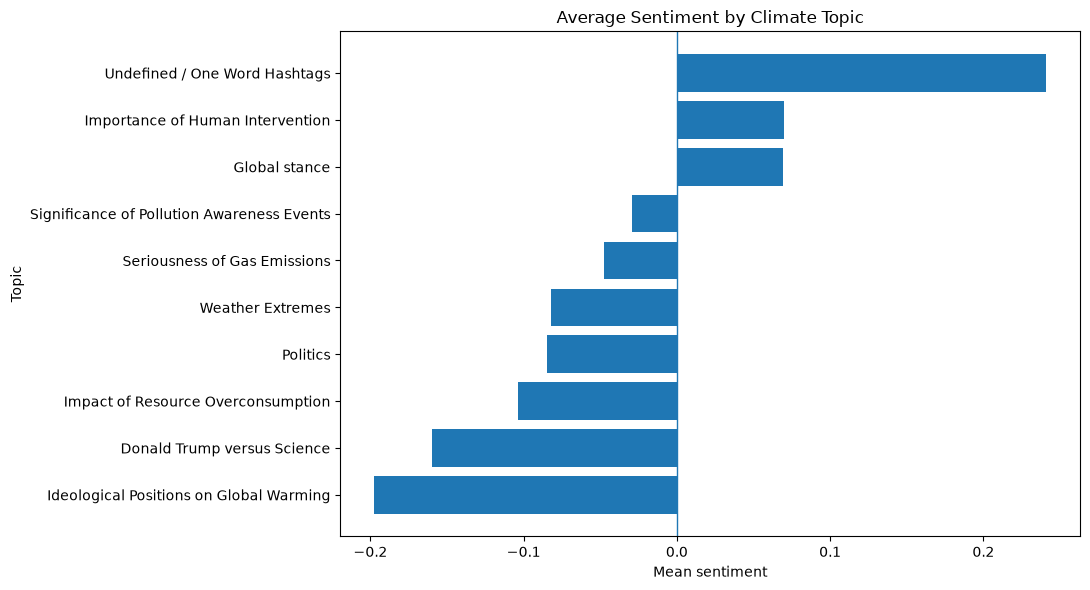

In [21]:
display(sentiment_by_topic)

plot_sent = sentiment_by_topic.sort_values("mean_sentiment")

plt.figure(figsize=(11, 6))
plt.barh(plot_sent["topic"], plot_sent["mean_sentiment"])
plt.axvline(0, linewidth=1)
plt.xlabel("Mean sentiment")
plt.ylabel("Topic")
plt.title("Average Sentiment by Climate Topic")
plt.tight_layout()
plt.show()

### Interpretation

Topic sentiment varies considerably. `Donald Trump versus Science` and `Ideological Positions on Global Warming` have relatively negative mean sentiment, while some broader stance/intervention and hashtag categories are more positive on average.

This reinforces the idea that climate discourse is not one homogeneous conversation: the tone varies depending on what people are discussing.

## 18. Gender distribution (descriptive only)

,gender,count,percent
0,male,10307402,65.280
1,female,4895134,31.003
2,undefined,586875,3.717


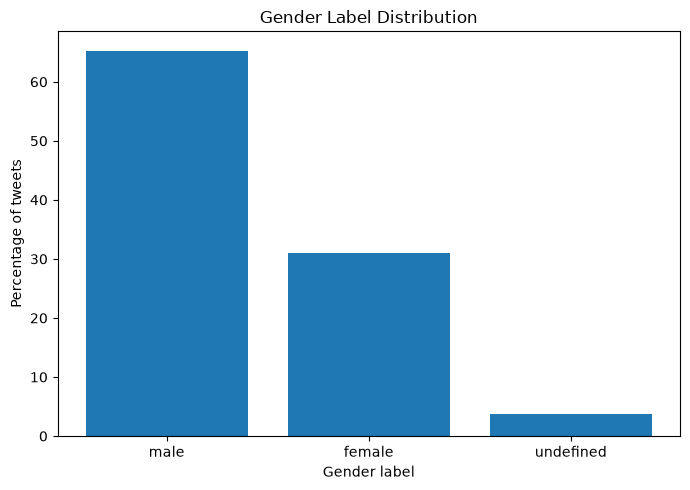

In [22]:
display(gender_df)

plt.figure(figsize=(7, 5))
plt.bar(gender_df["gender"], gender_df["percent"])
plt.xlabel("Gender label")
plt.ylabel("Percentage of tweets")
plt.title("Gender Label Distribution")
plt.tight_layout()
plt.show()

### Interpretation

About **65.3%** of tweets are labelled male, **31.0%** female, and **3.7%** undefined.

We keep this analysis descriptive because the dataset provides inferred gender labels rather than a complete representation of users' identities. A deeper gender-by-region analysis could be explored later, but it is not required for the main story developed here.

# Added sections for the proposal questions

Sections 19–29 use the counters collected in the same chunked pass as everything above, so no extra pass over the data is needed. Each section follows the same pattern: a question, one or two charts, and an interpretation cell to fill in after running.

## 19. Does the conversation react to climate events? (monthly volume)

Yearly totals hide spikes. We plot tweets per month from 2009 onward and mark well-known climate events.

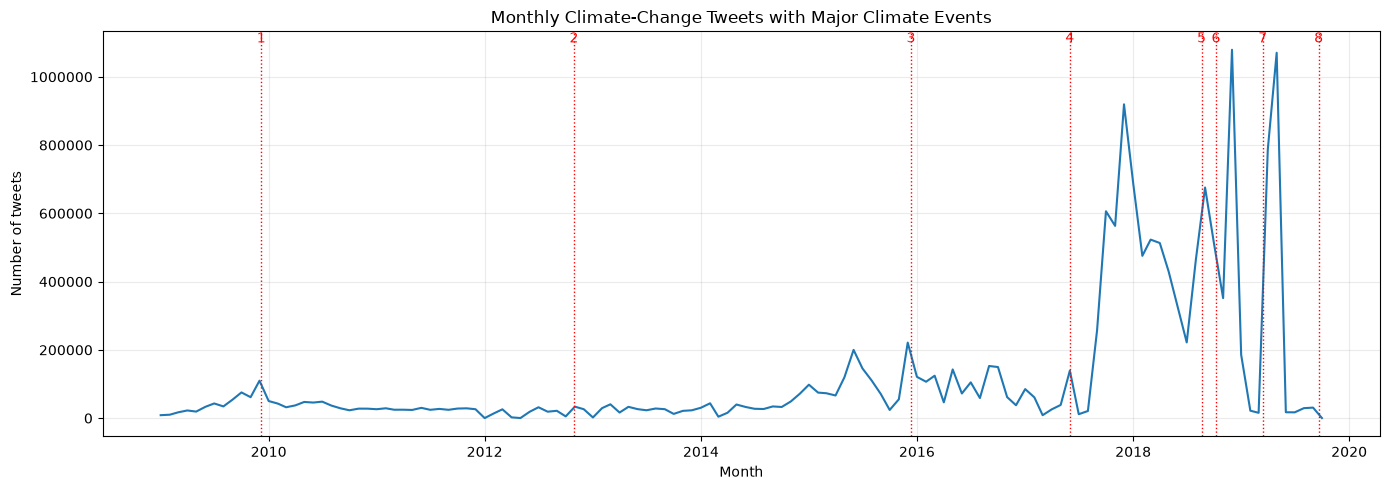

1: 2009-12-07  COP15 Copenhagen
2: 2012-10-29  Hurricane Sandy
3: 2015-12-12  Paris Agreement adopted
4: 2017-06-01  US announces Paris withdrawal
5: 2018-08-20  Greta Thunberg's first school strike
6: 2018-10-08  IPCC 1.5 C report
7: 2019-03-15  First global climate strike
8: 2019-09-20  Global climate strike / UN summit

Top 10 months:


2018-12    1079322
2019-05    1070467
2017-12     919408
2019-04     787273
2018-01     688579
2018-09     675712
2017-10     606113
2017-11     563279
2018-03     523059
2018-04     513139
Freq: M, Name: tweets, dtype: int64

In [23]:
monthly = pd.Series(month_counts)
monthly.index = pd.PeriodIndex(monthly.index, freq="M")
monthly = monthly.sort_index()
monthly = monthly[monthly.index >= pd.Period("2009-01", "M")]

events = {
    "2009-12-07": "COP15 Copenhagen",
    "2012-10-29": "Hurricane Sandy",
    "2015-12-12": "Paris Agreement adopted",
    "2017-06-01": "US announces Paris withdrawal",
    "2018-08-20": "Greta Thunberg's first school strike",
    "2018-10-08": "IPCC 1.5 C report",
    "2019-03-15": "First global climate strike",
    "2019-09-20": "Global climate strike / UN summit",
}

plt.figure(figsize=(14, 5))
plt.plot(monthly.index.to_timestamp(), monthly.values)
for i, (date, label) in enumerate(events.items(), start=1):
    plt.axvline(pd.Timestamp(date), color="red", linestyle=":", linewidth=1)
    plt.text(pd.Timestamp(date), monthly.max() * 1.02, str(i), color="red", ha="center")
plt.xlabel("Month")
plt.ylabel("Number of tweets")
plt.title("Monthly Climate-Change Tweets with Major Climate Events")
plt.ticklabel_format(style="plain", axis="y")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

for i, (date, label) in enumerate(events.items(), start=1):
    print(f"{i}: {date}  {label}")

print("\nTop 10 months:")
display(monthly.sort_values(ascending=False).head(10).rename("tweets"))

### Interpretation

- The monthly view has several large spikes, but the biggest ones do not consistently fall on the events we marked. The two largest months are **December 2018 (1,079,322 tweets)** and **May 2019 (1,070,467)**, each larger than all of 2009–2014 combined.
- Some months are almost empty because of gaps in the data collection: March, April, July and August 2017, and February, March, June and July 2019 hold only about 8,600–22,000 tweets each. This is why the September 2019 global strike (marker 8) shows no spike.
- So it is hard to tie individual spikes to particular events. What we can say confidently is that the overall level of climate discussion was much higher toward the end of the decade.

## 20. How did the topic mix change over time?

Section 11 plotted only the two political topics. Here every topic is shown as a share of its year's tweets (each year sums to 100%), using the `yt` table from section 7.

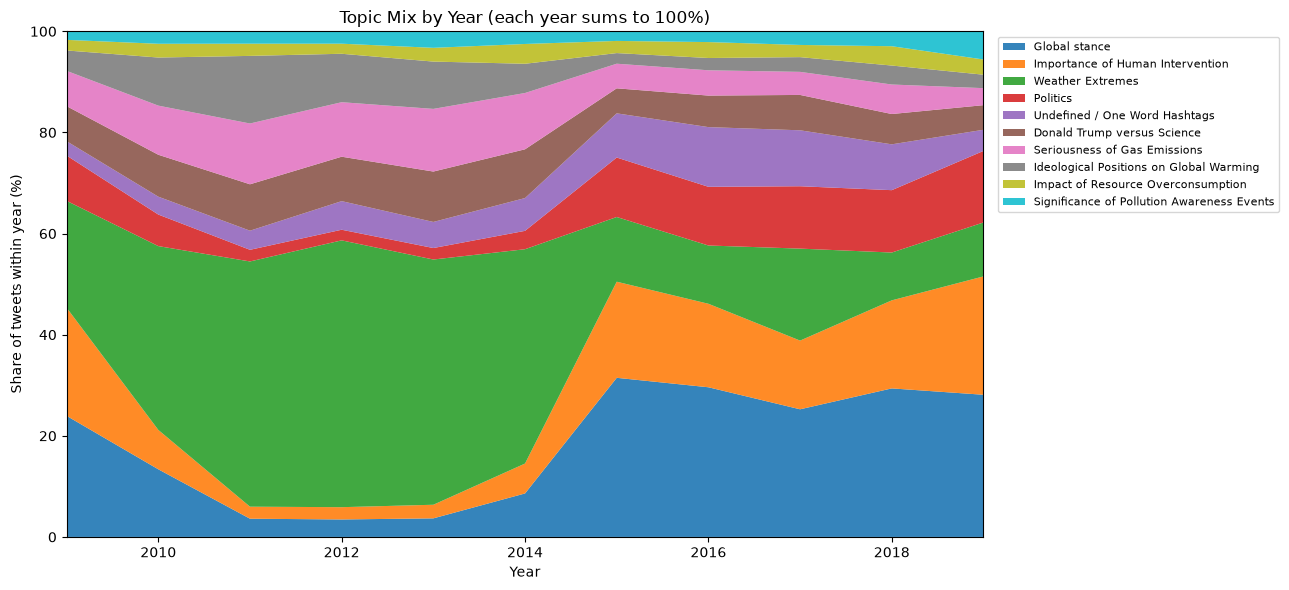

topic,Global stance,Importance of Human Intervention,Weather Extremes,Politics,Undefined / One Word Hashtags,Donald Trump versus Science,Seriousness of Gas Emissions,Ideological Positions on Global Warming,Impact of Resource Overconsumption,Significance of Pollution Awareness Events
year,,,,,,,,,,
2009,23.900,21.400,21.100,9.000,2.800,6.900,7.000,4.000,2.100,1.700
2010,13.400,7.800,36.400,6.200,3.500,8.300,9.700,9.500,2.700,2.500
2011,3.600,2.400,48.500,2.300,3.800,9.200,12.000,13.400,2.400,2.400
2012,3.500,2.400,52.800,2.100,5.700,8.800,10.800,9.600,2.000,2.400
2013,3.700,2.700,48.500,2.300,5.200,10.000,12.400,9.400,2.700,3.300
2014,8.600,5.900,42.400,3.600,6.500,9.600,11.100,5.800,3.900,2.500
2015,31.500,19.000,12.800,11.800,8.700,4.900,4.900,2.100,2.400,1.900
2016,29.600,16.500,11.500,11.600,11.800,6.200,5.000,2.400,3.200,2.100
2017,25.200,13.600,18.200,12.300,11.100,7.000,4.600,2.900,2.400,2.700


In [24]:
pivot_topics = yt[yt["year"] >= 2009].pivot(index="year", columns="topic", values="percent").fillna(0)
pivot_topics = pivot_topics[topic_df["topic"].tolist()]   # most frequent topic first

plt.figure(figsize=(13, 6))
plt.stackplot(pivot_topics.index, pivot_topics.T.values, labels=pivot_topics.columns, alpha=0.9)
plt.xlabel("Year")
plt.ylabel("Share of tweets within year (%)")
plt.title("Topic Mix by Year (each year sums to 100%)")
plt.xlim(pivot_topics.index.min(), pivot_topics.index.max())
plt.ylim(0, 100)
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.show()

display(pivot_topics.round(1))

### Interpretation

- In the early 2010s, **Weather Extremes** dominated the conversation (48–53% of tweets in 2011–2013).
- Around **2015** the pattern shifted: Weather Extremes fell to about 13%, while **Global stance** (31.5%), **Importance of Human Intervention** (19.0%) and **Politics** (11.8%) took up a much larger share, and the mix stayed similar through 2019.
- As the conversation grew, its focus moved from weather events toward broader debates about climate beliefs, human responsibility and politics. Because the change is so sharp, part of it may also reflect how the data was collected.

## 21. What does sentiment look like, and did the tone change over time?

First the full distribution of the sentiment score (an average near zero can mean "everyone is calm" or "half furious, half delighted"), then mean sentiment per year and the within-year share of negative / neutral / positive tweets.

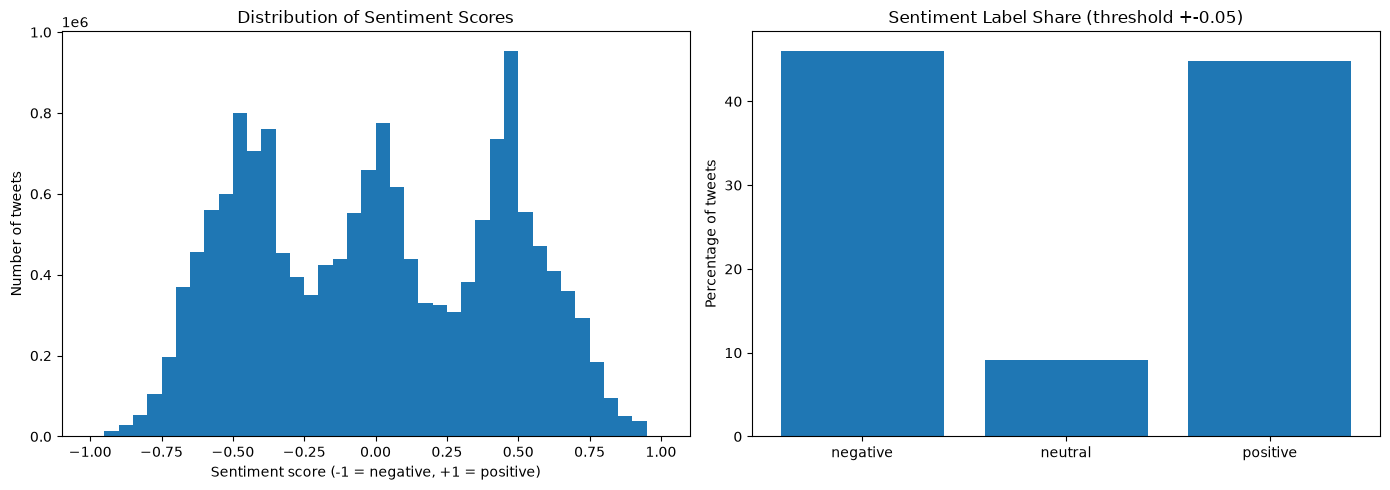

Mean sentiment over all tweets: 0.0025


negative   46.050
neutral     9.080
positive   44.870
dtype: float64

In [25]:
label_counts = Counter()
for (year, label), count in year_sentlabel.items():
    label_counts[label] += count
label_share = pd.Series(label_counts) / sum(label_counts.values()) * 100
label_share = label_share.reindex(["negative", "neutral", "positive"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
edges = np.linspace(-1, 1, 41)
axes[0].bar(edges[:-1], sent_hist, width=0.05, align="edge")
axes[0].set_xlabel("Sentiment score (-1 = negative, +1 = positive)")
axes[0].set_ylabel("Number of tweets")
axes[0].set_title("Distribution of Sentiment Scores")

axes[1].bar(label_share.index, label_share.values)
axes[1].set_ylabel("Percentage of tweets")
axes[1].set_title("Sentiment Label Share (threshold +-0.05)")
plt.tight_layout()
plt.show()

print(f"Mean sentiment over all tweets: {sent_sum / sent_n:.4f}")
display(label_share.round(2))

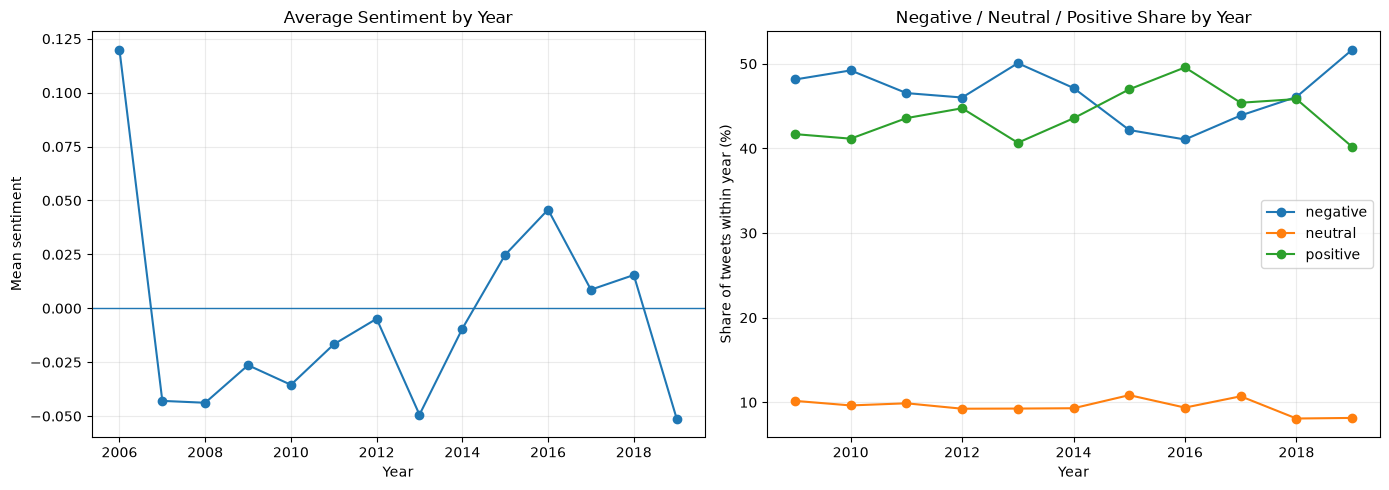

,year,mean_sentiment
0,2006,0.120
1,2007,-0.043
2,2008,-0.044
3,2009,-0.026
4,2010,-0.035
5,2011,-0.017
6,2012,-0.005
7,2013,-0.049
8,2014,-0.009
9,2015,0.025


sentiment_label,negative,neutral,positive
year,,,
2009,48.100,10.200,41.700
2010,49.200,9.600,41.200
2011,46.500,9.900,43.600
2012,46.000,9.200,44.700
2013,50.100,9.300,40.700
2014,47.100,9.300,43.600
2015,42.200,10.800,47.000
2016,41.100,9.400,49.600
2017,43.900,10.700,45.400


In [26]:
years_s = sorted(sent_by_year_sum)
sentiment_by_year = pd.DataFrame({
    "year": years_s,
    "mean_sentiment": [sent_by_year_sum[y] / sent_by_year_n[y] for y in years_s]
})

ysl = pd.Series(year_sentlabel).rename("count").reset_index()
ysl.columns = ["year", "sentiment_label", "count"]
ysl["year_total"] = ysl.groupby("year")["count"].transform("sum")
ysl["percent"] = ysl["count"] / ysl["year_total"] * 100
pivot_sl = ysl[ysl["year"] >= 2009].pivot(index="year", columns="sentiment_label", values="percent")
pivot_sl = pivot_sl[["negative", "neutral", "positive"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(sentiment_by_year["year"], sentiment_by_year["mean_sentiment"], marker="o")
axes[0].axhline(0, linewidth=1)
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Mean sentiment")
axes[0].set_title("Average Sentiment by Year")
axes[0].grid(alpha=0.25)

for col in pivot_sl.columns:
    axes[1].plot(pivot_sl.index, pivot_sl[col], marker="o", label=col)
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Share of tweets within year (%)")
axes[1].set_title("Negative / Neutral / Positive Share by Year")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

display(sentiment_by_year)
display(pivot_sl.round(1))

### Interpretation

- The sentiment distribution has three humps, around −0.5, 0 and +0.5, which likely reflects how the ensemble of sentiment models combines its predictions.
- Overall, **46.1%** of tweets are negative, **44.9%** positive and only **9.1%** neutral, so the overall mean of **+0.003** hides two large opposing groups.
- Over time there is no steady trend: sentiment became somewhat more positive in the mid-2010s (positive tweets outnumber negative ones in 2015–2016) and then moved the other way, with **2019 the most negative year** (51.7% negative, mean −0.051).

## 22. Which topics attract deniers?

`topic_stance` was already collected in section 5 but not yet plotted. Each topic is shown as its own stance composition (rows sum to 100%), sorted by denier share.

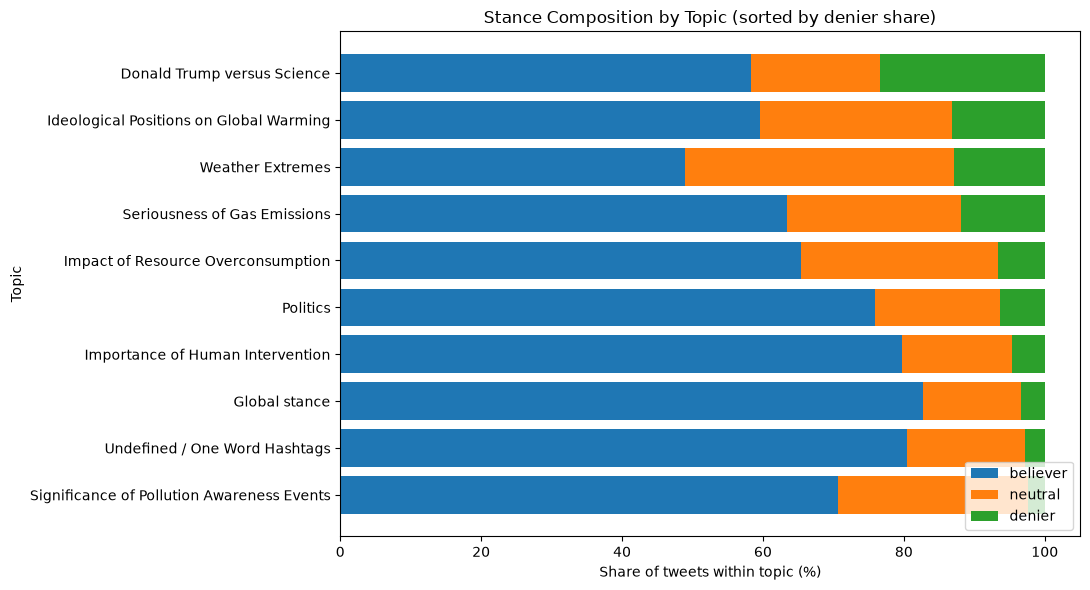

stance,believer,neutral,denier
topic,,,
Donald Trump versus Science,58.400,18.300,23.300
Ideological Positions on Global Warming,59.500,27.300,13.200
Weather Extremes,48.900,38.200,12.900
Seriousness of Gas Emissions,63.500,24.600,11.900
Impact of Resource Overconsumption,65.400,28.000,6.600
Politics,75.900,17.800,6.300
Importance of Human Intervention,79.700,15.700,4.600
Global stance,82.700,14.000,3.400
Undefined / One Word Hashtags,80.500,16.700,2.800


In [27]:
ts = pd.Series(topic_stance).rename("count").reset_index()
ts.columns = ["topic", "stance", "count"]
ts["topic_total"] = ts.groupby("topic")["count"].transform("sum")
ts["percent"] = ts["count"] / ts["topic_total"] * 100

pivot_ts = ts.pivot(index="topic", columns="stance", values="percent")[["believer", "neutral", "denier"]]
pivot_ts = pivot_ts.sort_values("denier")

plt.figure(figsize=(11, 6))
left = np.zeros(len(pivot_ts))
for col in pivot_ts.columns:
    plt.barh(pivot_ts.index, pivot_ts[col], left=left, label=col)
    left += pivot_ts[col].values
plt.xlabel("Share of tweets within topic (%)")
plt.ylabel("Topic")
plt.title("Stance Composition by Topic (sorted by denier share)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

display(pivot_ts.sort_values("denier", ascending=False).round(1))

### Interpretation

- Denial is most common in **Donald Trump versus Science (23.3%)**, **Ideological Positions (13.2%)** and **Weather Extremes (12.9%)**, all well above the overall denier share of 7.5%.
- It is least common in **Global stance (3.4%)**, **Importance of Human Intervention (4.6%)** and **Pollution Awareness Events (2.4%)**.
- Weather Extremes is also the most neutral topic (38.2% neutral).

## 23. Did aggressiveness rise *within* each stance, and within political topics?

Section 16 showed the overall aggressive share falling after 2015. Here we split it by stance, and — for denier tweets only — by political topics (Politics, Donald Trump versus Science) versus all other topics.

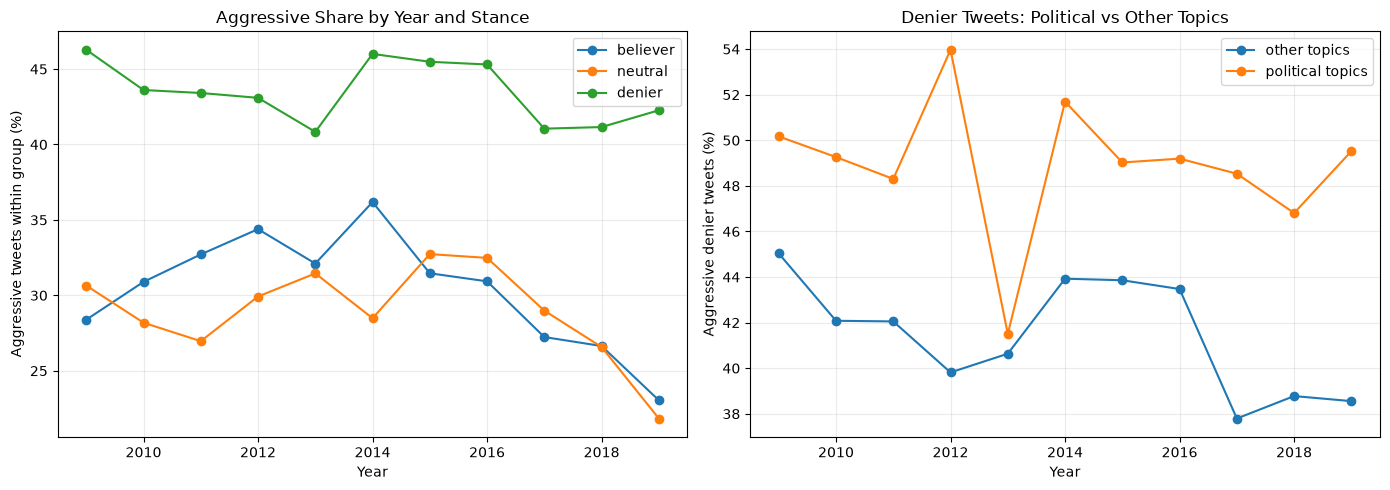

stance,believer,neutral,denier
year,,,
2009,28.400,30.600,46.300
2010,30.900,28.200,43.600
2011,32.700,27.000,43.400
2012,34.400,29.900,43.100
2013,32.100,31.500,40.800
2014,36.200,28.500,46.000
2015,31.500,32.700,45.500
2016,30.900,32.500,45.300
2017,27.200,29.000,41.000


political,other topics,political topics
year,,
2009,45.000,50.200
2010,42.100,49.300
2011,42.100,48.300
2012,39.800,54.000
2013,40.600,41.500
2014,43.900,51.700
2015,43.900,49.000
2016,43.500,49.200
2017,37.800,48.500


In [28]:
ysa = pd.Series(year_stance_aggr).rename("count").reset_index()
ysa.columns = ["year", "stance", "aggressiveness", "count"]
ysa["group_total"] = ysa.groupby(["year", "stance"])["count"].transform("sum")
ysa["percent"] = ysa["count"] / ysa["group_total"] * 100
pivot_ysa = (
    ysa[(ysa["aggressiveness"] == "aggressive") & (ysa["year"] >= 2009)]
    .pivot(index="year", columns="stance", values="percent")[["believer", "neutral", "denier"]]
)

yspa = pd.Series(year_stance_pol_aggr).rename("count").reset_index()
yspa.columns = ["year", "stance", "political", "aggressiveness", "count"]
yspa = yspa[yspa["stance"] == "denier"].copy()
yspa["group_total"] = yspa.groupby(["year", "political"])["count"].transform("sum")
yspa["percent"] = yspa["count"] / yspa["group_total"] * 100
pivot_pol = (
    yspa[(yspa["aggressiveness"] == "aggressive") & (yspa["year"] >= 2009)]
    .pivot(index="year", columns="political", values="percent")
    .rename(columns={True: "political topics", False: "other topics"})
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for col in pivot_ysa.columns:
    axes[0].plot(pivot_ysa.index, pivot_ysa[col], marker="o", label=col)
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Aggressive tweets within group (%)")
axes[0].set_title("Aggressive Share by Year and Stance")
axes[0].legend()
axes[0].grid(alpha=0.25)

for col in pivot_pol.columns:
    axes[1].plot(pivot_pol.index, pivot_pol[col], marker="o", label=col)
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Aggressive denier tweets (%)")
axes[1].set_title("Denier Tweets: Political vs Other Topics")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

display(pivot_ysa.round(1))
display(pivot_pol.round(1))

### Interpretation

- The overall decline in aggressiveness (section 16) comes from believers and neutrals: believer tweets fell from 31.5% aggressive in 2015 to **23.0%** in 2019, and neutral tweets from 32.7% to **21.8%**.
- Denier tweets did not calm down: they stay between **41% and 46%** aggressive in every year.
- For denier tweets, political topics were consistently the most aggressive (**47–54%**), while non-political denier tweets fell from 43.9% in 2015 to 38.6% in 2019. The gap widened from about 5 to 11 points because non-political discussion calmed down, not because political discussion heated up.
- So climate Twitter became louder, but not angrier: the growing share of less aggressive believer tweets brought the overall rate down.

## 24. Which topics are aggressive *for each stance*?

A heatmap of the aggressive share by topic × stance separates "deniers are angrier" from "politics is angrier".

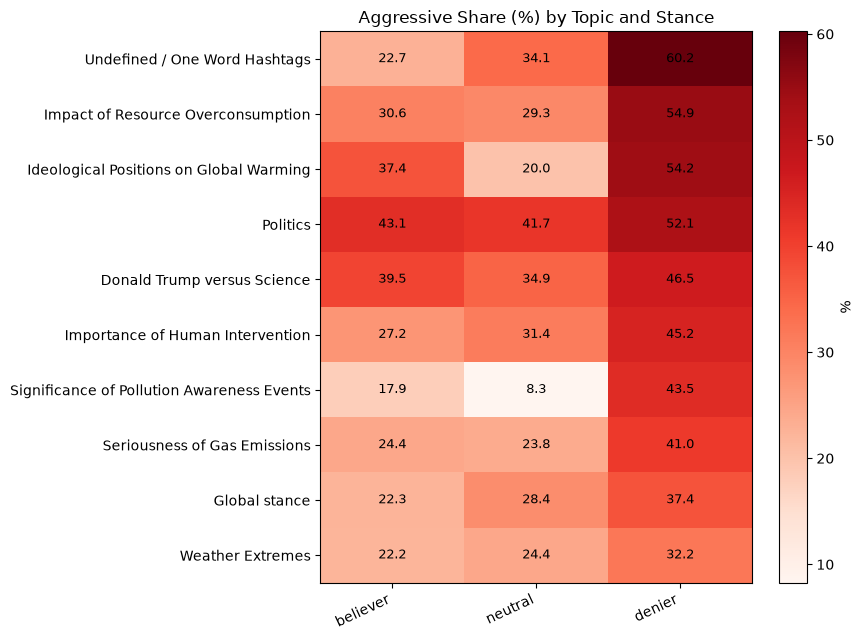

stance,believer,neutral,denier,denier minus believer (pp)
topic,,,,
Undefined / One Word Hashtags,22.700,34.100,60.200,37.500
Impact of Resource Overconsumption,30.600,29.300,54.900,24.300
Ideological Positions on Global Warming,37.400,20.000,54.200,16.800
Politics,43.100,41.700,52.100,9.100
Donald Trump versus Science,39.500,34.900,46.500,6.900
Importance of Human Intervention,27.200,31.400,45.200,18.000
Significance of Pollution Awareness Events,17.900,8.300,43.500,25.500
Seriousness of Gas Emissions,24.400,23.800,41.000,16.600
Global stance,22.300,28.400,37.400,15.100


In [29]:
def plot_heatmap(table, title, cmap="Reds", fmt="{:.1f}", min_count=None, counts=None):
    # Simple matplotlib heatmap with the values written in each cell.
    values = table.values.astype(float)
    if counts is not None:
        values = np.where(counts.values >= min_count, values, np.nan)
    plt.figure(figsize=(1.6 * table.shape[1] + 4, 0.45 * table.shape[0] + 2))
    plt.imshow(values, cmap=cmap, aspect="auto")
    plt.colorbar(label="%")
    plt.xticks(range(table.shape[1]), table.columns, rotation=25, ha="right")
    plt.yticks(range(table.shape[0]), table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            if not np.isnan(values[i, j]):
                plt.text(j, i, fmt.format(values[i, j]), ha="center", va="center", fontsize=9)
    plt.title(title)
    plt.tight_layout()
    plt.show()


tsa = pd.Series(topic_stance_aggr).rename("count").reset_index()
tsa.columns = ["topic", "stance", "aggressiveness", "count"]
tsa["group_total"] = tsa.groupby(["topic", "stance"])["count"].transform("sum")
tsa["percent"] = tsa["count"] / tsa["group_total"] * 100
pivot_tsa = (
    tsa[tsa["aggressiveness"] == "aggressive"]
    .pivot(index="topic", columns="stance", values="percent")[["believer", "neutral", "denier"]]
    .sort_values("denier", ascending=False)
)

plot_heatmap(pivot_tsa, "Aggressive Share (%) by Topic and Stance")

pivot_tsa["denier minus believer (pp)"] = pivot_tsa["denier"] - pivot_tsa["believer"]
display(pivot_tsa.round(1))

### Interpretation

- Denier tweets are more aggressive than believer tweets in **every** topic.
- The largest gaps are in non-political topics, such as one-word hashtags (**60.2% vs 22.7%**) and Pollution Awareness (**43.5% vs 17.9%**).
- In political topics aggression is high for everyone: in Politics, 52.1% of denier tweets and 43.1% of believer tweets are aggressive.
- Both stance and topic are associated with aggressiveness. Since both labels come from classifiers that may react to similar language, this is an association, not a causal relationship.

## 25. The gender gap in denial and aggressiveness

Stance composition and aggressive share within each gender label (gender is an inferred label, so this stays descriptive).

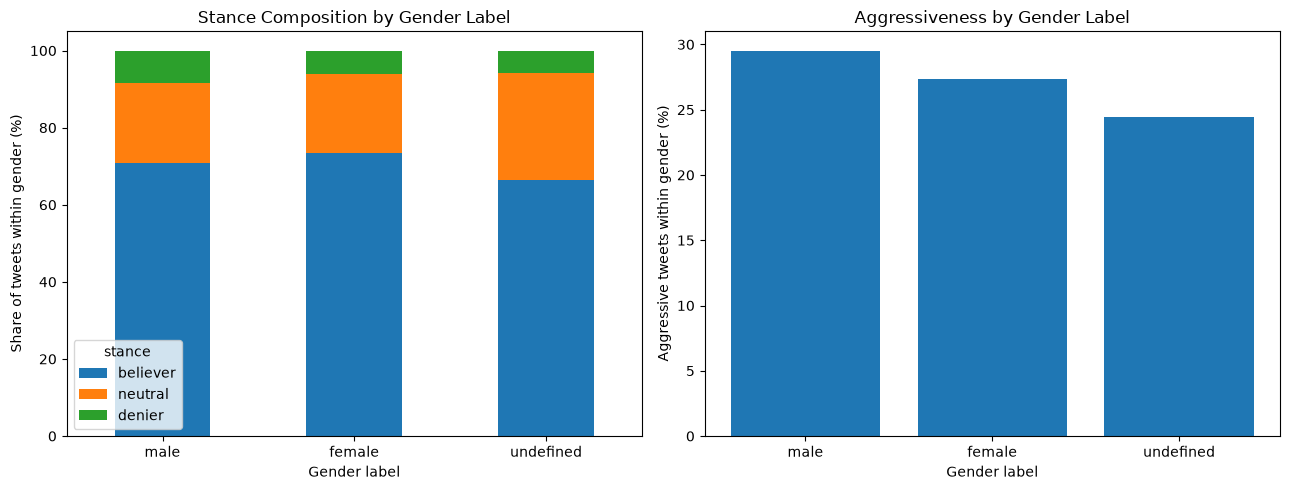

stance,believer,neutral,denier
gender,,,
male,70.830,20.780,8.390
female,73.560,20.460,5.980
undefined,66.520,27.690,5.800


gender
male        29.530
female      27.380
undefined   24.460
Name: percent, dtype: float64

Gender gap in denial (male minus female, percentage points): 2.40


In [30]:
gs = pd.Series(gender_stance).rename("count").reset_index()
gs.columns = ["gender", "stance", "count"]
gs["group_total"] = gs.groupby("gender")["count"].transform("sum")
gs["percent"] = gs["count"] / gs["group_total"] * 100
pivot_gs = gs.pivot(index="gender", columns="stance", values="percent")[["believer", "neutral", "denier"]]
pivot_gs = pivot_gs.reindex(["male", "female", "undefined"])

ga = pd.Series(gender_aggr).rename("count").reset_index()
ga.columns = ["gender", "aggressiveness", "count"]
ga["group_total"] = ga.groupby("gender")["count"].transform("sum")
ga["percent"] = ga["count"] / ga["group_total"] * 100
aggressive_by_gender = (
    ga[ga["aggressiveness"] == "aggressive"].set_index("gender")["percent"].reindex(["male", "female", "undefined"])
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pivot_gs.plot(kind="bar", stacked=True, ax=axes[0], rot=0)
axes[0].set_ylabel("Share of tweets within gender (%)")
axes[0].set_xlabel("Gender label")
axes[0].set_title("Stance Composition by Gender Label")

axes[1].bar(aggressive_by_gender.index, aggressive_by_gender.values)
axes[1].set_ylabel("Aggressive tweets within gender (%)")
axes[1].set_xlabel("Gender label")
axes[1].set_title("Aggressiveness by Gender Label")
plt.tight_layout()
plt.show()

display(pivot_gs.round(2))
display(aggressive_by_gender.round(2))
gender_gap_pp = pivot_gs.loc["male", "denier"] - pivot_gs.loc["female", "denier"]
print(f"Gender gap in denial (male minus female, percentage points): {gender_gap_pp:.2f}")

### Interpretation

- **8.4%** of male-labelled tweets are classified as denier, against **6.0%** of female-labelled tweets: a gap of **2.4 percentage points** (1.4 times as likely).
- The gap in aggressiveness is smaller: **29.5%** vs **27.4%**. Aggression varies much more by stance (42.6% for deniers vs 27.3% for believers) than by the gender assigned by the model.
- Gender is a classifier's guess from names and profiles, so we treat these results descriptively. Section 27 checks whether the gap is the same in every region.

## 26. Where do climate tweets come from?

Only about a third of tweets have coordinates (section 6). We first check whether that third is biased in time, then map it and compare regions. The map is a 1° world grid of tweet counts built during the chunked pass — the tweets themselves draw the continents.

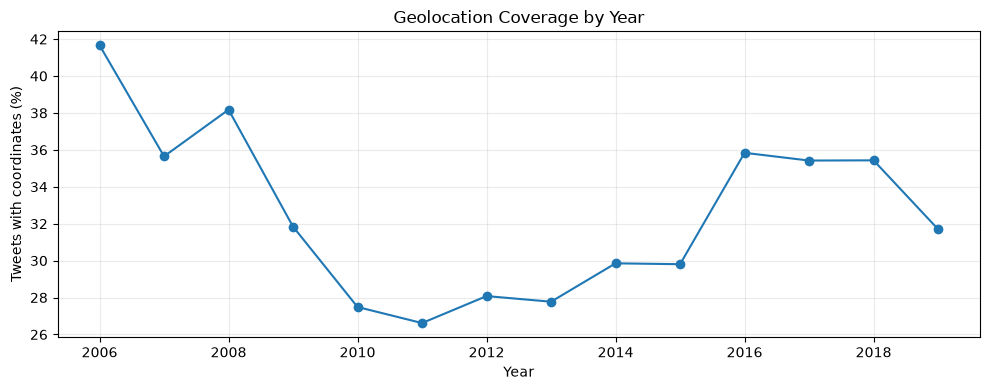

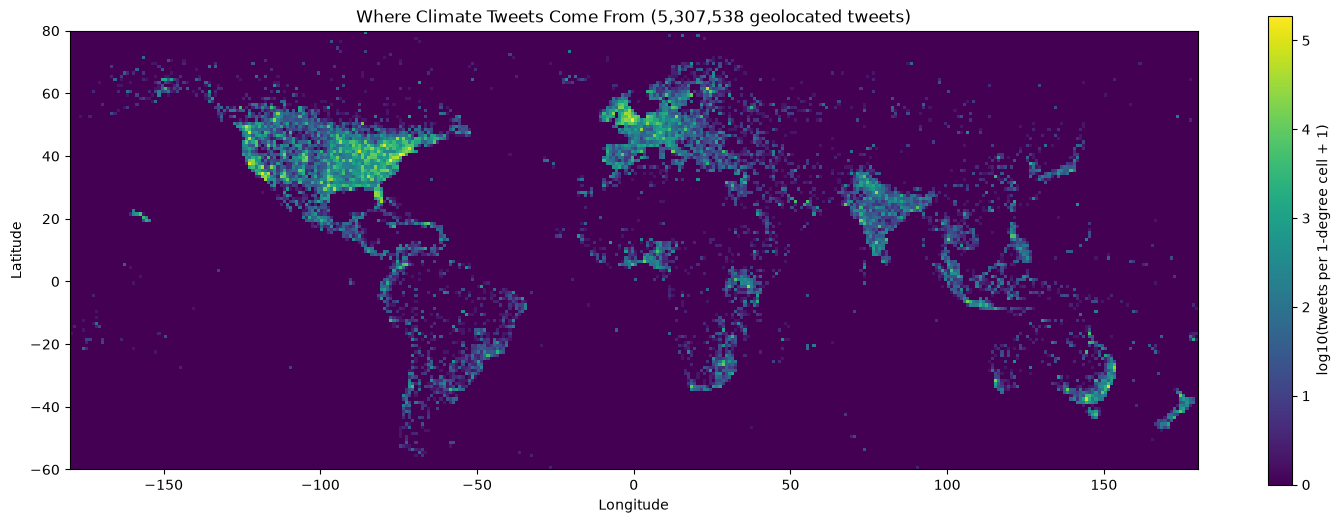

In [31]:
yg = pd.Series(year_geo).rename("count").reset_index()
yg.columns = ["year", "has_geo", "count"]
yg["year_total"] = yg.groupby("year")["count"].transform("sum")
yg["percent"] = yg["count"] / yg["year_total"] * 100
geo_coverage = yg[yg["has_geo"] == True].set_index("year")["percent"]

plt.figure(figsize=(10, 4))
plt.plot(geo_coverage.index, geo_coverage.values, marker="o")
plt.xlabel("Year")
plt.ylabel("Tweets with coordinates (%)")
plt.title("Geolocation Coverage by Year")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 7))
plt.imshow(np.log10(geo_grid + 1), origin="lower", extent=[-180, 180, -90, 90], cmap="viridis", aspect="equal")
plt.colorbar(label="log10(tweets per 1-degree cell + 1)", shrink=0.7)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"Where Climate Tweets Come From ({int(geo_grid.sum()):,} geolocated tweets)")
plt.ylim(-60, 80)
plt.tight_layout()
plt.show()

,region,count,percent_of_geolocated
0,North America,3453307,65.064
1,Europe,1035344,19.507
2,Oceania,333090,6.276
3,Asia,263876,4.972
5,Africa & Middle East,141016,2.657
4,Latin America,78900,1.487
6,Other,2005,0.038


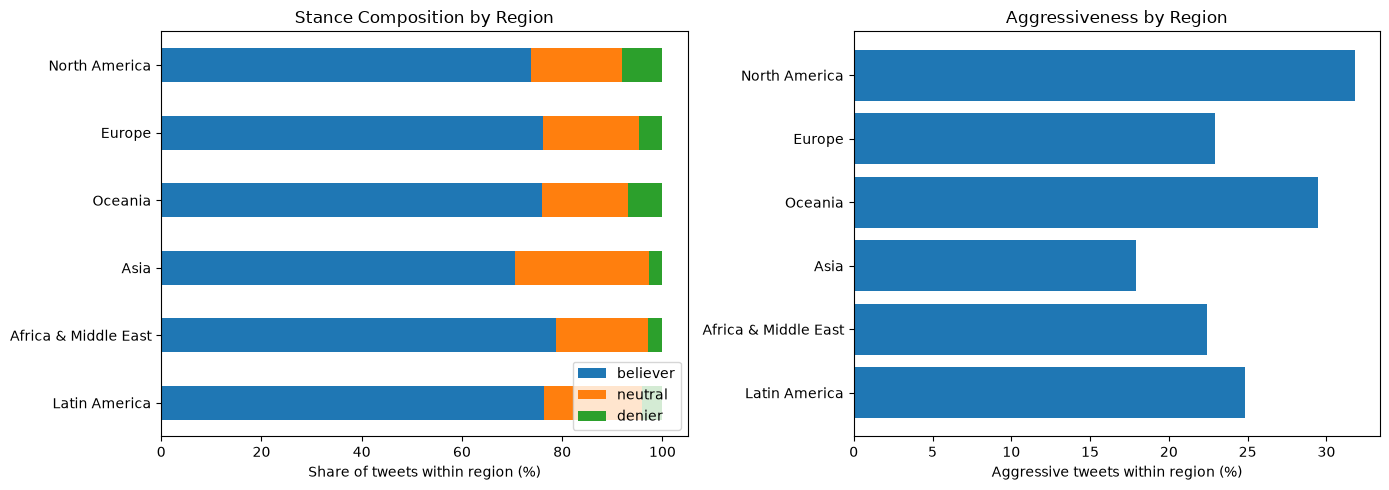

stance,believer,neutral,denier
region,,,
North America,73.800,18.100,8.100
Europe,76.100,19.300,4.600
Oceania,76.000,17.100,6.900
Asia,70.600,26.700,2.700
Africa & Middle East,78.700,18.500,2.800
Latin America,76.300,19.600,4.200


region
North America          31.800
Europe                 22.900
Oceania                29.500
Asia                   17.900
Africa & Middle East   22.400
Latin America          24.800
Name: percent, dtype: float64

In [32]:
region_df = pd.DataFrame(region_counts.items(), columns=["region", "count"]).sort_values("count", ascending=False)
region_df["percent_of_geolocated"] = region_df["count"] / region_df["count"].sum() * 100
display(region_df)

regions = [r for r in region_df["region"] if r != "Other"]   # the six named regions, largest first

rs = pd.Series(region_stance).rename("count").reset_index()
rs.columns = ["region", "stance", "count"]
rs["group_total"] = rs.groupby("region")["count"].transform("sum")
rs["percent"] = rs["count"] / rs["group_total"] * 100
pivot_rs = rs.pivot(index="region", columns="stance", values="percent")[["believer", "neutral", "denier"]].reindex(regions)

ra = pd.Series(region_aggr).rename("count").reset_index()
ra.columns = ["region", "aggressiveness", "count"]
ra["group_total"] = ra.groupby("region")["count"].transform("sum")
ra["percent"] = ra["count"] / ra["group_total"] * 100
aggressive_by_region = ra[ra["aggressiveness"] == "aggressive"].set_index("region")["percent"].reindex(regions)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pivot_rs.plot(kind="barh", stacked=True, ax=axes[0])
axes[0].set_xlabel("Share of tweets within region (%)")
axes[0].set_ylabel("")
axes[0].set_title("Stance Composition by Region")
axes[0].invert_yaxis()
axes[0].legend(loc="lower right")

axes[1].barh(aggressive_by_region.index, aggressive_by_region.values)
axes[1].set_xlabel("Aggressive tweets within region (%)")
axes[1].set_title("Aggressiveness by Region")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

display(pivot_rs.round(1))
display(aggressive_by_region.round(1))

### Interpretation

- Geolocation coverage is not constant but has no clear trend: it falls from about 32% in 2009 to 26.6% in 2011, rises to about 36% in 2016–2018, and is 32% in 2019.
- The map mostly shows Twitter's English-speaking world: the eastern United States and the UK are brightest, India, eastern Australia and Nigeria stand out, and China, Russia and the Sahara are almost empty.
- **North America** makes up 65.1% of located tweets, Europe 19.5%, Oceania 6.3%, Asia 5.0%, Africa & Middle East 2.7% and Latin America 1.5%.
- North America and Oceania are the most denier-heavy (8.1% and 6.9%) and the most aggressive (31.8% and 29.5%). Asia is the most neutral (26.7%) and the calmest (17.9% aggressive).
- Coordinates come from users' *profile* locations (median error ≈ 24 km) and regions are coarse bounding boxes, so this supports continent-level comparisons, not country claims.

## 27. Does the gender gap in denial hold in every region?

Denier share for male- vs female-labelled tweets within each region (geolocated tweets only).

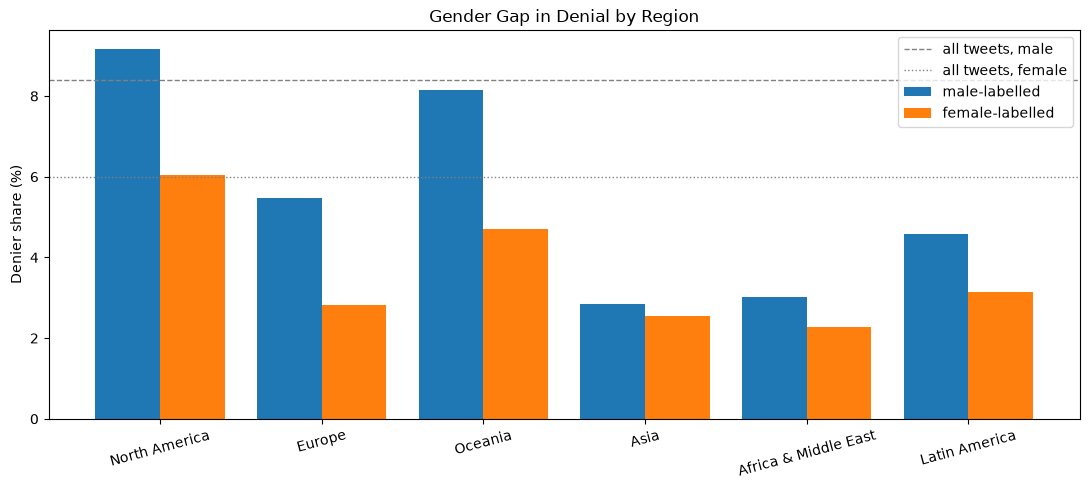

gender,male,female,gap_pp (male - female),tweets
region,,,,
North America,9.170,6.040,3.130,3367594
Europe,5.460,2.820,2.650,1012205
Oceania,8.150,4.720,3.440,300951
Asia,2.850,2.550,0.300,250373
Africa & Middle East,3.010,2.270,0.740,135316
Latin America,4.590,3.130,1.460,76994


In [33]:
rgs = pd.Series(region_gender_stance).rename("count").reset_index()
rgs.columns = ["region", "gender", "stance", "count"]
rgs = rgs[rgs["gender"].isin(["male", "female"])].copy()
rgs["group_total"] = rgs.groupby(["region", "gender"])["count"].transform("sum")
rgs["percent"] = rgs["count"] / rgs["group_total"] * 100
gap_by_region = (
    rgs[rgs["stance"] == "denier"]
    .pivot(index="region", columns="gender", values="percent")[["male", "female"]]
    .reindex(regions)
)
gap_by_region["gap_pp (male - female)"] = gap_by_region["male"] - gap_by_region["female"]
gap_by_region["tweets"] = rgs.groupby("region")["count"].sum().reindex(regions)

x = np.arange(len(regions))
plt.figure(figsize=(11, 5))
plt.bar(x - 0.2, gap_by_region["male"], width=0.4, label="male-labelled")
plt.bar(x + 0.2, gap_by_region["female"], width=0.4, label="female-labelled")
plt.axhline(pivot_gs.loc["male", "denier"], linestyle="--", linewidth=1, color="grey", label="all tweets, male")
plt.axhline(pivot_gs.loc["female", "denier"], linestyle=":", linewidth=1, color="grey", label="all tweets, female")
plt.xticks(x, regions, rotation=15)
plt.ylabel("Denier share (%)")
plt.title("Gender Gap in Denial by Region")
plt.legend()
plt.tight_layout()
plt.show()

display(gap_by_region.round(2))

### Interpretation

- Male-labelled tweets are more likely to be denier in **all six regions**, but the size of the gap varies a lot: **3.4 points** in Oceania, **3.1** in North America, **2.7** in Europe, 1.5 in Latin America, 0.7 in Africa & Middle East and only **0.3** in Asia.
- The gap is larger where denial is more common overall. The difference *between regions* (2.7% denier in Asia vs 8.1% in North America) is about twice the overall gender gap.
- Africa & Middle East and Latin America have few located tweets, so their gaps are the least reliable.

## 28. Do the same topics attract denial and aggression in every region?

Denier share and aggressive share by topic × region. Cells with fewer than 500 tweets are left blank. A Spearman rank correlation between each region's topic ranking and the global ranking summarises how consistent the pattern is.

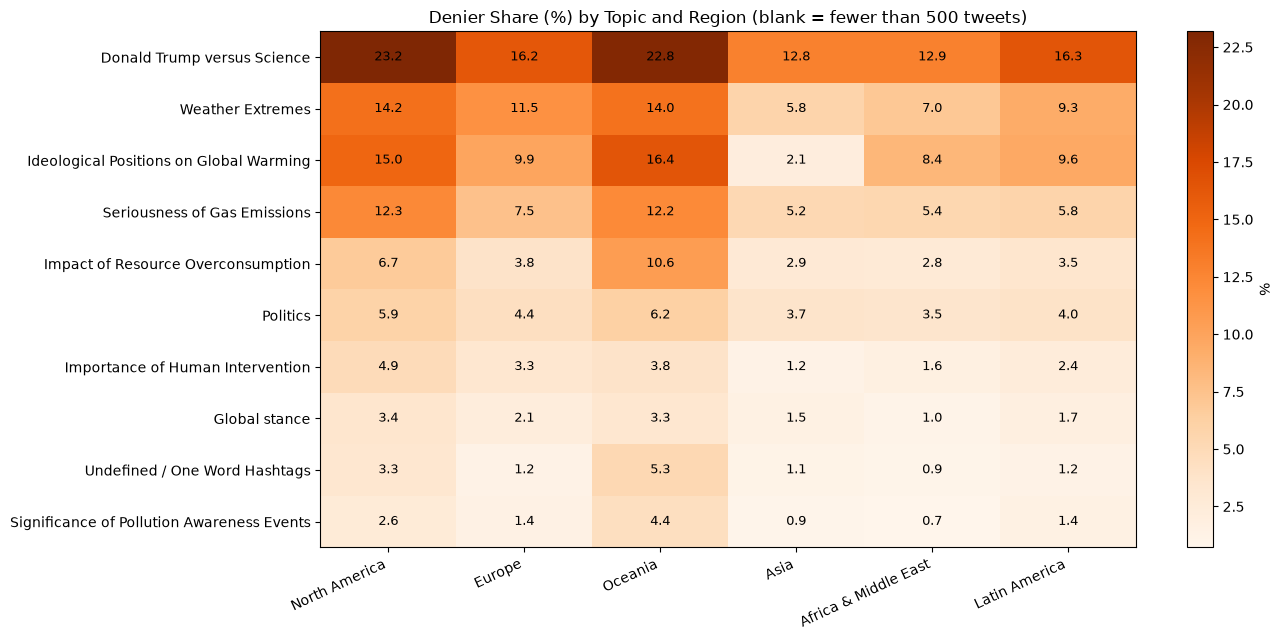

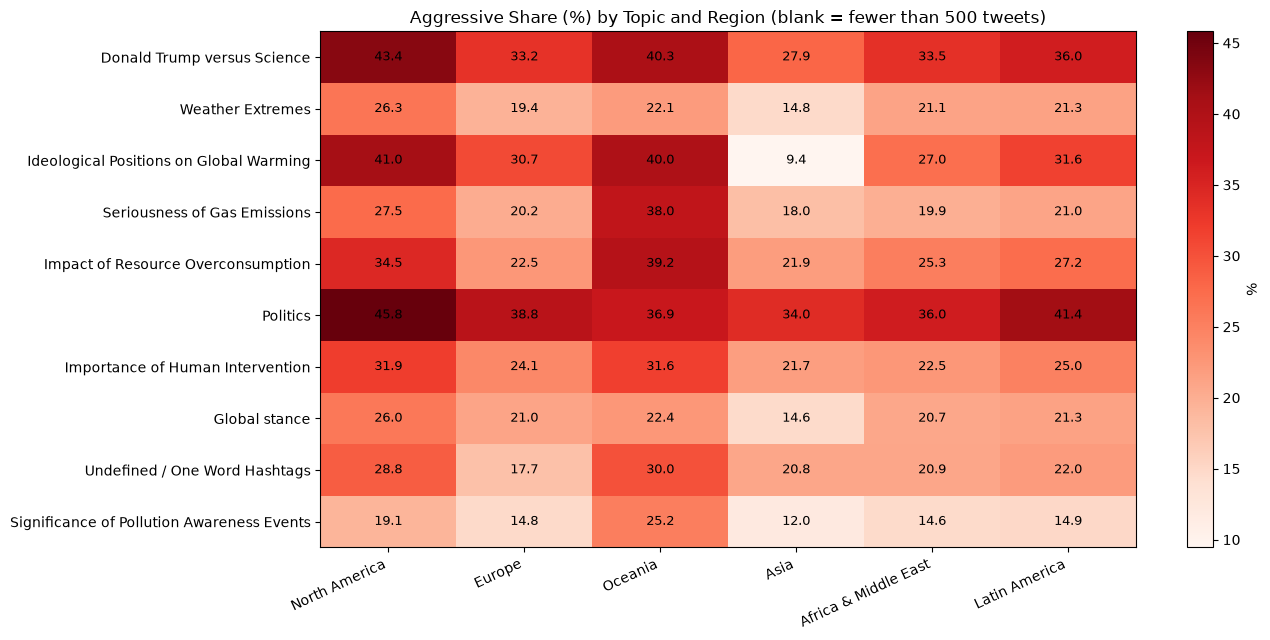

,denier ranking vs global (Spearman),aggressive ranking vs global (Spearman)
North America,1.000,0.990
Europe,0.960,0.900
Oceania,0.900,0.810
Asia,0.850,0.650
Africa & Middle East,0.990,0.920
Latin America,0.980,0.920


In [34]:
rts = pd.Series(region_topic_stance).rename("count").reset_index()
rts.columns = ["region", "topic", "stance", "count"]
rts["group_total"] = rts.groupby(["region", "topic"])["count"].transform("sum")
rts["percent"] = rts["count"] / rts["group_total"] * 100
denier_tr = rts[rts["stance"] == "denier"].pivot(index="topic", columns="region", values="percent")[regions]
counts_tr = rts.groupby(["topic", "region"])["count"].sum().unstack()[regions].reindex(denier_tr.index)

rta = pd.Series(region_topic_aggr).rename("count").reset_index()
rta.columns = ["region", "topic", "aggressiveness", "count"]
rta["group_total"] = rta.groupby(["region", "topic"])["count"].transform("sum")
rta["percent"] = rta["count"] / rta["group_total"] * 100
aggr_tr = rta[rta["aggressiveness"] == "aggressive"].pivot(index="topic", columns="region", values="percent")[regions]
aggr_tr = aggr_tr.reindex(denier_tr.index)

order = denier_tr.mean(axis=1).sort_values(ascending=False).index
plot_heatmap(denier_tr.loc[order], "Denier Share (%) by Topic and Region (blank = fewer than 500 tweets)",
             cmap="Oranges", min_count=500, counts=counts_tr.loc[order])
plot_heatmap(aggr_tr.loc[order], "Aggressive Share (%) by Topic and Region (blank = fewer than 500 tweets)",
             cmap="Reds", min_count=500, counts=counts_tr.loc[order])

# How consistent is each region's topic ranking with the global ranking?
global_denier = pivot_ts["denier"]                       # from section 22
global_aggr = ta[ta["aggressiveness"] == "aggressive"].set_index("topic")["percent"]   # from section 7
consistency = pd.DataFrame({
    "denier ranking vs global (Spearman)": {r: denier_tr[r].corr(global_denier, method="spearman") for r in regions},
    "aggressive ranking vs global (Spearman)": {r: aggr_tr[r].corr(global_aggr, method="spearman") for r in regions},
})
display(consistency.round(2))

### Interpretation

- The topic ranking for denial is almost the same in every region (Spearman **0.85–1.00**), and **Donald Trump versus Science** has the highest denier share everywhere (23.2% in North America, 16.2% in Europe, 12.8% in Asia).
- The ranking for aggression is also similar (**0.81–0.99**), except in **Asia (0.65)**, where Ideological Positions is unusually calm (9.4% aggressive). Politics or Trump versus Science is the most aggressive topic in every region.
- Verdict for Q5: the same topics attract denial and aggression everywhere, but the level depends on the region. North America's denier share is about 1.8 times Europe's and three times Asia's.

## 29. Does an unusually warm (or cold) month change what people say?

`temperature_avg` is the temperature **anomaly** (°C relative to the 1951–1980 average at that place and month), so a positive mean is expected — the 2010s were warmer than the mid-20th century. The question is whether *unusually* hot or cold months change stance, tone, or topics, and whether that differs between believers, deniers, and neutral users (proposal Q6).

Tweets with a temperature anomaly: 5,307,538
Mean anomaly: 1.25 C | std: 3.80 | min: -23.29 | max: 21.00
Share of tweets sent in a warmer-than-baseline month: 64.9%


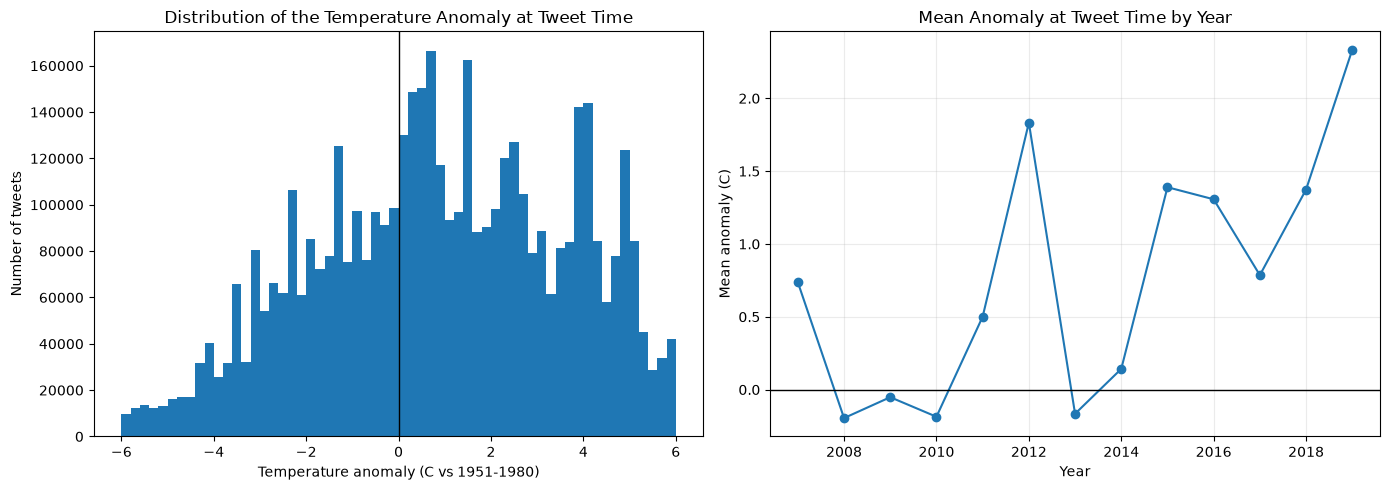

,year,mean_anomaly,tweets
1,2007,0.740,1412
2,2008,-0.200,11445
3,2009,-0.050,155716
4,2010,-0.190,123110
5,2011,0.500,84608
6,2012,1.830,55789
7,2013,-0.170,78454
8,2014,0.140,121933
9,2015,1.390,375359
10,2016,1.310,422599


In [35]:
temp_mean = temp_sum / temp_n
temp_std = np.sqrt(temp_sumsq / temp_n - temp_mean ** 2)
print(f"Tweets with a temperature anomaly: {temp_n:,}")
print(f"Mean anomaly: {temp_mean:.2f} C | std: {temp_std:.2f} | min: {temp_min:.2f} | max: {temp_max:.2f}")
print(f"Share of tweets sent in a warmer-than-baseline month: {temp_above_zero / temp_n * 100:.1f}%")

years_t = sorted(temp_by_year_sum)
anomaly_by_year = pd.DataFrame({
    "year": years_t,
    "mean_anomaly": [temp_by_year_sum[y] / temp_by_year_n[y] for y in years_t],
    "tweets": [temp_by_year_n[y] for y in years_t],
})
anomaly_by_year = anomaly_by_year[anomaly_by_year["tweets"] >= 1000]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bin_edges = np.linspace(-6, 6, 61)
axes[0].bar(bin_edges[:-1], temp_hist, width=0.2, align="edge")
axes[0].axvline(0, linewidth=1, color="black")
axes[0].set_xlabel("Temperature anomaly (C vs 1951-1980)")
axes[0].set_ylabel("Number of tweets")
axes[0].set_title("Distribution of the Temperature Anomaly at Tweet Time")

axes[1].plot(anomaly_by_year["year"], anomaly_by_year["mean_anomaly"], marker="o")
axes[1].axhline(0, linewidth=1, color="black")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Mean anomaly (C)")
axes[1].set_title("Mean Anomaly at Tweet Time by Year")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()
display(anomaly_by_year.round(2))

,tweets,denier_percent,aggressive_percent,mean_sentiment,weather_extremes_percent
<= -3,595268,9.710,30.810,-0.020,22.560
-3 to -1,785663,7.160,29.790,0.010,13.320
-1 to 0,480735,6.520,28.510,0.040,13.890
0 to 1,692882,6.080,27.860,0.040,12.970
1 to 3,1060905,6.270,28.530,0.030,12.570
> 3,1692085,6.580,28.530,0.010,13.730


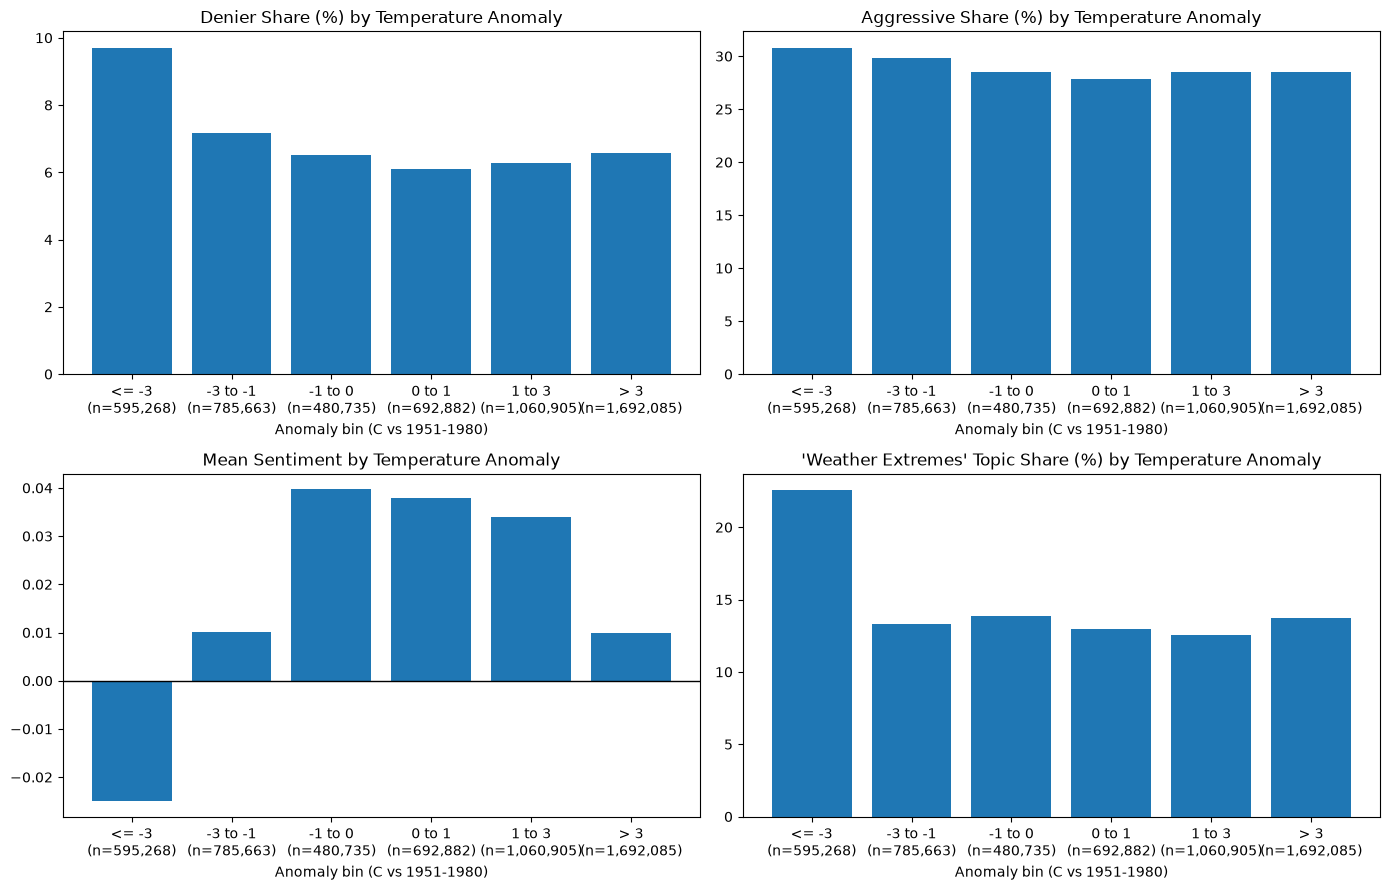

Pearson correlation between temperature anomaly and sentiment: r = +0.0174 (n = 5,307,538)


In [36]:
bin_order = ["<= -3", "-3 to -1", "-1 to 0", "0 to 1", "1 to 3", "> 3"]

bs = pd.Series(bin_stance).rename("count").reset_index()
bs.columns = ["temp_bin", "stance", "count"]
bs["group_total"] = bs.groupby("temp_bin")["count"].transform("sum")
bs["percent"] = bs["count"] / bs["group_total"] * 100

ba = pd.Series(bin_aggr).rename("count").reset_index()
ba.columns = ["temp_bin", "aggressiveness", "count"]
ba["group_total"] = ba.groupby("temp_bin")["count"].transform("sum")
ba["percent"] = ba["count"] / ba["group_total"] * 100

bt = pd.Series(bin_topic).rename("count").reset_index()
bt.columns = ["temp_bin", "topic", "count"]
bt["group_total"] = bt.groupby("temp_bin")["count"].transform("sum")
bt["percent"] = bt["count"] / bt["group_total"] * 100

by_bin = pd.DataFrame({
    "tweets": pd.Series(bin_counts),
    "denier_percent": bs[bs["stance"] == "denier"].set_index("temp_bin")["percent"],
    "aggressive_percent": ba[ba["aggressiveness"] == "aggressive"].set_index("temp_bin")["percent"],
    "mean_sentiment": pd.Series({k: sent_by_bin_sum[k] / sent_by_bin_n[k] for k in sent_by_bin_sum}),
    "weather_extremes_percent": bt[bt["topic"] == "Weather Extremes"].set_index("temp_bin")["percent"],
}).reindex(bin_order)
display(by_bin.round(2))

labels = [f"{b}\n(n={int(n):,})" for b, n in zip(by_bin.index, by_bin["tweets"].fillna(0))]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col, title in zip(
    axes.ravel(),
    ["denier_percent", "aggressive_percent", "mean_sentiment", "weather_extremes_percent"],
    ["Denier Share (%)", "Aggressive Share (%)", "Mean Sentiment", "'Weather Extremes' Topic Share (%)"],
):
    ax.bar(labels, by_bin[col])
    ax.set_title(f"{title} by Temperature Anomaly")
    ax.set_xlabel("Anomaly bin (C vs 1951-1980)")
    if col == "mean_sentiment":
        ax.axhline(0, linewidth=1, color="black")
plt.tight_layout()
plt.show()

# Pearson correlation between anomaly and sentiment, from the running sums collected in the chunk loop
n = corr["n"]
r = (n * corr["xy"] - corr["x"] * corr["y"]) / np.sqrt(
    (n * corr["xx"] - corr["x"] ** 2) * (n * corr["yy"] - corr["y"] ** 2)
)
print(f"Pearson correlation between temperature anomaly and sentiment: r = {r:+.4f} (n = {n:,})")

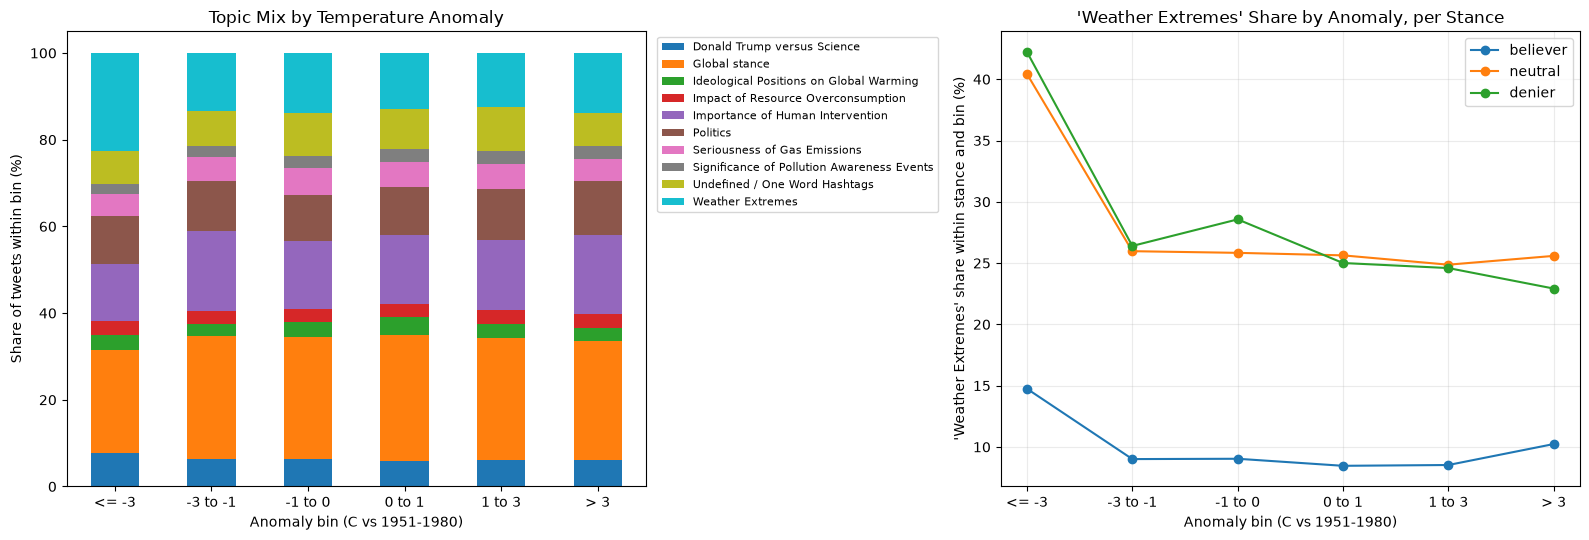

stance,believer,neutral,denier
temp_bin,,,
<= -3,14.750,40.430,42.220
-3 to -1,9.010,25.970,26.400
-1 to 0,9.030,25.840,28.570
0 to 1,8.460,25.630,25.010
1 to 3,8.520,24.870,24.590
> 3,10.230,25.590,22.920


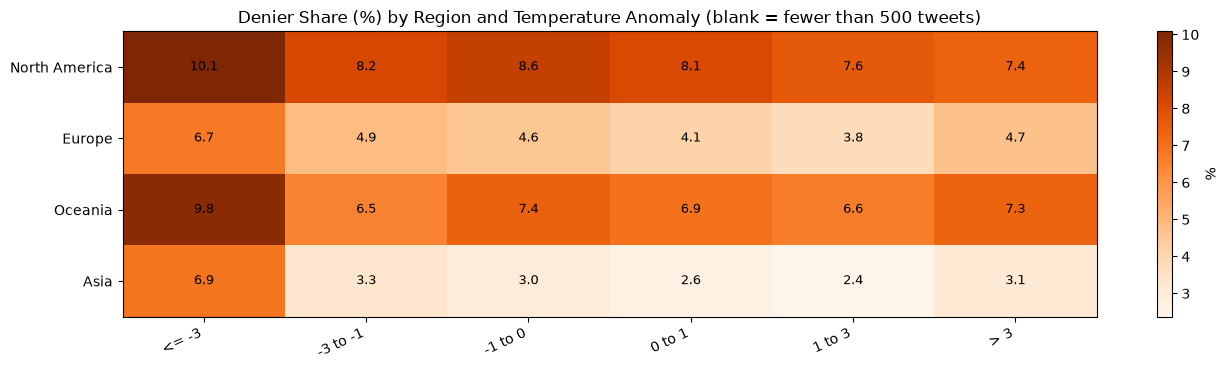

In [37]:
# Does the 'Weather Extremes' response differ by stance?
bst = pd.Series(bin_stance_topic).rename("count").reset_index()
bst.columns = ["temp_bin", "stance", "topic", "count"]
bst["group_total"] = bst.groupby(["temp_bin", "stance"])["count"].transform("sum")
bst["percent"] = bst["count"] / bst["group_total"] * 100
we_by_stance = (
    bst[bst["topic"] == "Weather Extremes"]
    .pivot(index="temp_bin", columns="stance", values="percent")[["believer", "neutral", "denier"]]
    .reindex(bin_order)
)

# Full topic mix per anomaly bin
pivot_bt = bt.pivot(index="temp_bin", columns="topic", values="percent").reindex(bin_order)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
pivot_bt.plot(kind="bar", stacked=True, ax=axes[0], rot=0)
axes[0].set_ylabel("Share of tweets within bin (%)")
axes[0].set_xlabel("Anomaly bin (C vs 1951-1980)")
axes[0].set_title("Topic Mix by Temperature Anomaly")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

for col in we_by_stance.columns:
    axes[1].plot(we_by_stance.index, we_by_stance[col], marker="o", label=col)
axes[1].set_ylabel("'Weather Extremes' share within stance and bin (%)")
axes[1].set_xlabel("Anomaly bin (C vs 1951-1980)")
axes[1].set_title("'Weather Extremes' Share by Anomaly, per Stance")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()
display(we_by_stance.round(2))

# Region x anomaly: is where you tweet from a bigger factor than how hot it is?
brs = pd.Series(bin_region_stance).rename("count").reset_index()
brs.columns = ["temp_bin", "region", "stance", "count"]
brs["group_total"] = brs.groupby(["temp_bin", "region"])["count"].transform("sum")
brs["percent"] = brs["count"] / brs["group_total"] * 100
denier_rb = (
    brs[brs["stance"] == "denier"]
    .pivot(index="region", columns="temp_bin", values="percent")
    .reindex(index=[r for r in regions if r in ("North America", "Europe", "Asia", "Oceania")], columns=bin_order)
)
counts_rb = brs.groupby(["region", "temp_bin"])["count"].sum().unstack().reindex(index=denier_rb.index, columns=bin_order)
plot_heatmap(denier_rb, "Denier Share (%) by Region and Temperature Anomaly (blank = fewer than 500 tweets)",
             cmap="Oranges", min_count=500, counts=counts_rb)

### Interpretation

- The anomaly averages **+1.25 °C** and **64.9%** of located tweets were sent in a warmer-than-baseline month, as expected for the 2010s. The yearly mean is near zero in 2008–2010 and 2013, +1.8 °C in 2012 and +2.3 °C in 2019.
- We expected a heat effect and found a **cold effect**. Only the coldest bin (≤ −3 °C, 595,268 tweets) stands out: denier share **9.7%** (vs 6.1–7.2%), aggressive share 30.8% (vs 27.9–29.8%), mean sentiment −0.02 (vs +0.01 to +0.04), and Weather Extremes share **22.6%** (vs 12.6–13.9%). Unusually warm months look like normal ones.
- At the tweet level the link is weak: Pearson r between anomaly and sentiment is **+0.017**.
- The cold-month shift comes mostly from the unconvinced: in the coldest months the Weather Extremes share rises to 42.2% for denier and 40.4% for neutral tweets, but only to 14.8% for believers.
- The coldest bin has the highest denier share in every region, but the regions differ more from each other than the bins do.
- Caveats: the anomaly is monthly and regional, not the weather on the day, and year, stance, region and temperature are entangled, so these results are descriptive, not causal.

# 30. Key findings

The EDA suggests five main findings:

1. **Climate-change discussion grew dramatically over the dataset period**, with the later years contributing most observations. 2018 alone accounts for roughly 39.6% of all tweets.
2. **Believer-labelled tweets dominate the dataset**, particularly from 2015 onward.
3. **Politics becomes a larger share of climate discussion in later years**, reaching about 14.2% of tweets in 2019.
4. **Aggressiveness is strongly associated with stance and topic.** Around 42.6% of denier tweets are aggressive, compared with about 27.3% of believer tweets. Politics and Donald Trump versus Science are also the two most aggressive topics.
5. **The overall climate conversation does not become steadily more aggressive.** Despite the high aggressiveness of political categories, the total aggressive share declines in the later years.

### A possible Medium-blog thesis

> **Climate Twitter became increasingly political, but not simply more hostile. Political topics were among the most aggressive parts of the discussion, while the overall share of aggressive tweets actually fell in the later years. Meanwhile, stance composition shifted strongly toward believer-labelled tweets.**

This gives the article a stronger story than simply presenting independent charts.

### Additional findings from sections 19–29

6. **Timeline:** the biggest months (December 2018 and May 2019, about 1.07 million tweets each) do not line up neatly with the marked events, and several months in 2017 and 2019 are nearly empty because of collection gaps.
7. **Topic shift:** around 2015 the conversation moved from Weather Extremes to Global stance, Human Intervention and Politics.
8. **Tone over time:** no steady trend; positive in 2015–2016, most negative in 2019 (51.7% negative tweets).
9. **Louder, not angrier:** the drop in aggressiveness comes from believers and neutrals; denier tweets stay at 41–46% aggressive every year.
10. **Gender gap:** male-labelled tweets are 1.4 times as likely to be denier (8.4% vs 6.0%); the gap appears in every region but is largest in Oceania, North America and Europe and almost zero in Asia.
11. **Geography:** the same topics attract denial and aggression on every continent (Spearman 0.85–1.00 for denial), but North America and Oceania have the most of both.
12. **Temperature:** unusually warm months change little, but months at least 3 °C colder than normal raise the denier share and nearly double Weather Extremes tweets, mainly among denier and neutral tweets.

# 31. Limitations

The findings should be interpreted carefully.

- **Twitter users are not representative of the general population**, so these results cannot be treated as public-opinion estimates.
- The dataset contains far more tweets in later years than early years. We therefore use within-year percentages for many temporal comparisons.
- The earliest years contain very few tweets, making percentages unstable.
- There are known gaps in data collection (several months in 2017 and 2019 are nearly empty), so not every rise or fall in activity reflects a real change in public discussion.
- Geographic coordinates and the temperature anomaly are missing for about two-thirds of tweets, so geographic or temperature conclusions rely on a smaller, self-selected subset (users who filled in a profile location).
- `temperature_avg` is a monthly, regional anomaly, not the weather on the day of the tweet; and hot anomalies cluster in the late years, so year and temperature effects are entangled in the descriptive comparisons.
- Stance, sentiment, topic, gender, and aggressiveness are dataset labels/inferences. Associations between these labels do not establish causality.
- This EDA describes patterns within this dataset; it does not prove why those patterns occurred.

These limitations are important to include in the Medium post so the analysis does not overclaim.

# 32. Conclusion

Looking across all six questions, the biggest finding is that the climate conversation on Twitter did not just grow; it changed. Weather-focused discussion became less dominant, broader questions about climate stance and human intervention became more prominent, and politics took up a larger share.

Some of our original expectations turned out to be too simple. Politics became a bigger part of the conversation, but the discussion did not become more evenly polarised: believer tweets became much more common, while denier tweets did not grow. Political topics were generally more aggressive, yet aggression became *less* common during the years when the conversation grew most.

Geographically, the same topics attracted denial and aggression in every region, but the strength of those patterns varied. Unusually warm months changed the conversation very little, while unusually cold months were linked with more Weather Extremes discussion, especially among neutral and denier tweets.

The next stage (Checkpoint 4) will test these patterns more carefully:
- whether climate stance can be predicted from topic, region, date, temperature anomaly and gender,
- whether the cold-weather pattern still holds after accounting for year and region,
- and whether the decline in aggressiveness came from changes in who was tweeting or from groups becoming less aggressive themselves.